# WildSpeech V2 — Robust Acoustic & Phonetic Intelligence (P16–P22)

**Central question.** Can robust, phonetic and expected-text-conditioned speech representations explain future reading outcomes *beyond the strongest conventional literacy-assessment baseline*?

This notebook is the single interface for execution, results, scientific analysis and figures of the V2 research line. All computation lives in `src/wildspeech/` (harmonization, correctness, phonetic, reference, foundation, models, diagnostics, v2, stages).

* `RUN_PIPELINE = False` (default): nothing is computed — every section only **displays** what earlier runs produced (or says that a stage has not run).
* `RUN_PIPELINE = True`: each section runs its stage if its switch in `RUN` is on. Dependencies are resolved automatically; unchanged stages are `cached`; interrupted extractions resume from their checkpoints; stale upstream artefacts are re-run before they are consumed.
* V2 profiles only override the `v2` configuration section, so the completed **P00–P15 artefacts are reused and never recomputed** by this notebook.
* Test inference is disabled unless `RUN_SUBMISSION = True` in section 15.
* Every interpretation printed below is generated from the tables of the current run (`wildspeech.v2.research_report_v2`); nothing is pre-written.

In [1]:
import os, sys, json, time
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "configs" / "default.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / "configs" / "default.yaml").exists(), "open this notebook from inside the WildSpeech_GPU repository"
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("PYTHONUTF8", "1")
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 240)
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
%matplotlib inline
print("repository:", ROOT)

repository: C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU


---
## 1 · Configuration and hardware diagnostics
Profiles: `V2_SMOKE` (technical check), `V2_CORE` (P16, P17, P19, P21, P22), `V2_PHONETIC` (+P18), `V2_FOUNDATION` (+P20), `V2_FULL` (all). P18 / P20 only use local checkpoints with `license_verified` and `overlap_checked` set in `configs/foundation_models.yaml`.

In [19]:
RUN_PIPELINE = True          # True = display existing results only; True = run the enabled stages
PROFILE = "V2_FULL"           # V2_SMOKE | V2_CORE | V2_PHONETIC | V2_FOUNDATION | V2_FULL
RUN = {                       # per-stage switches (used only when RUN_PIPELINE is True)
    "P16": True,   # acoustic domain harmonization
    "P18": True,   # phonetic & linguistic intelligence (needs eligible local models)
    "P20": True,   # foundation-model discovery (needs eligible local models)
    "P17": True,   # clip-level correctness intelligence
    "P19": True,   # reference-conditioned speech
    "P21": True,   # compact multimodal regression
    "P22": True,   # failure recovery + champion selection (+ report)
}
FORCE = []                    # stage ids to recompute even if cached, e.g. ["P21"]
REUSE_ARTIFACTS = True        # True = ignore stage-level caching (fold/feature caches are still reused)
OVERRIDES = {
    # "v2": {"evaluation": {"bootstrap": 500}, "multimodal": {"budgets": [5, 10, 20]}},
}
RUN_SUBMISSION = True        # section 15: test inference with the selected candidates (after reviewing P22)
TABLE_ROWS = 12
SHOW_ALL_TABLES = True       # True = every table of each stage, not only the key ones
if not REUSE_ARTIFACTS:
    OVERRIDES.setdefault("runtime", {})["resume"] = True

In [20]:
from wildspeech.v2.notebook import figure_atlas, run_stage, setup_v2, show_stage_v2
from wildspeech.hardware import compatibility_notes, hardware_report

ctx, pipe = setup_v2(PROFILE, OVERRIDES, root=ROOT)
RUN_LOG = []
print("profile:", PROFILE, "| device:", ctx.device, "| data:", ctx.paths.data_dir)
hw = hardware_report()
display(pd.DataFrame([{k: (json.dumps(v, default=str)[:160] if isinstance(v, (dict, list)) else v) for k, v in hw.items()}]).T.rename(columns={0: "value"}))
for note in compatibility_notes(hw):
    print("note:", note)
display(Markdown("**V2 configuration (top level)**"))
display(pd.DataFrame([{"section": k, "settings": json.dumps(v, default=str)[:220]} for k, v in ctx.cfg.get("v2", {}).items()]))
display(Markdown("**Plan for this profile** (dry run — nothing executed)"))
display(pipe.run(None, force=FORCE, dry_run=True))

17:18:33 | INFO    | context: profile=V2_FULL device=cuda root=C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU data=C:\Users\myben\Downloads\WildSpeech_P01\data


profile: V2_FULL | device: cuda | data: C:\Users\myben\Downloads\WildSpeech_P01\data


,value
os,Windows-10-10.0.26300-SP0
python,3.10.18
executable,c:\Users\myben\.conda\envs\MITSUI\python.exe
conda_env,MITSUI
cpu,"AMD64 Family 25 Model 80 Stepping 0, AuthenticAMD"
logical_cpus,16
physical_cpus,8
ram_total_gb,16.54
ram_available_gb,1.014
cpu_max_mhz,3301


note: RTX 30xx (sm_86): fp16 autocast is efficient; TF32 matmul enabled for embeddings.
note: 8 GB VRAM: keep base-size foundation models, fp16, batch <= 8 for 20 s crops.
note: Windows: no multiprocessing workers are used (threads only); DataLoader num_workers=0.


**V2 configuration (top level)**

,section,settings
0,project,"{""version"": ""2.0.0"", ""output_dir"": ""outputs/V2..."
1,runtime,"{""refresh_stale_soft_deps"": true, ""enforce_fre..."
2,validation,"{""schemes"": [""repeated_kfold"", ""school_kfold"",..."
3,evaluation,"{""baseline"": ""auto"", ""baseline_fallback"": {""mo..."
4,harmonization,"{""enabled"": true, ""selected"": ""auto"", ""splits""..."
5,correctness,"{""enabled"": true, ""feature_sets"": [""META"", ""LI..."
6,phonetic,"{""enabled"": true, ""require_verification"": true..."
7,reference,"{""enabled"": true, ""variant"": ""auto"", ""frame_ho..."
8,foundation,"{""enabled"": true, ""models"": [""wav2vec2_base"", ..."
9,multimodal,"{""enabled"": true, ""budgets"": [5, 10, 20, 50, 1..."


**Plan for this profile** (dry run — nothing executed)

,stage,status,note
0,P00,cached,2026-11-20T14:09:49
1,P01,cached,2026-11-20T14:10:08
2,P16,would_run,acoustic domain harmonization + item-condition...
3,P18,would_run,content-conditioned phonetic analysis (ASR / C...
4,P20,would_run,frozen speech foundation-model representations...
5,P17,would_run,clip-level correctness intelligence (nested cr...
6,P19,would_run,reference-conditioned speech modelling (templa...
7,P21,would_run,compact multimodal student-level regression
8,P22,would_run,"failure recovery, deployability checks, champi..."


---
## 2 · Existing artifact inventory
Status, freshness and outputs of every stage P00–P22, and the V1 / V2 feature caches (V2 caches live in `cache/v2` so V1 builders never see them).

In [21]:
from wildspeech.v2.inventory import cache_inventory, stage_inventory

inv = stage_inventory(ctx)
display(inv)
display(Markdown(f"**Stale completed stages** (fingerprint changed since they ran): {', '.join(inv.loc[inv['up_to_date'] == False, 'stage']) or 'none'}"))
display(cache_inventory(ctx))

,stage,status,up_to_date,finished,seconds,profile,n_tables,n_figures,dir,note
0,P00,completed,True,2026-11-20T14:09:49,24.05,FULL,10,1,outputs\P00_infrastructure,
1,P01,completed,True,2026-11-20T14:10:08,19.08,FULL,16,8,outputs\P01_tabular_eda,
2,P02,completed,True,2026-11-20T14:12:27,138.7,FULL,10,5,outputs\P02_acoustic_eda,
3,P03,disabled,None,2026-11-20T14:20:57,0,FULL,0,0,outputs\P03_phonetic,phonetic.enabled=false
4,P04,disabled,None,2026-11-20T14:20:59,0,FULL,0,0,outputs\P04_embeddings,embeddings.enabled=false
5,P05,completed,True,2026-11-20T14:17:35,7.513,FULL,3,1,outputs\P05_features,
6,P06,completed,True,2026-11-20T14:19:09,18.35,FULL,11,3,outputs\P06_phenotypes,
7,P07,completed,True,2026-11-20T14:20:20,71.3,FULL,8,2,outputs\P07_residual_discovery,
8,P08,completed,False,2026-11-20T15:12:24,3052,FULL,17,2,outputs\P08_robustness,
9,P09,completed,True,2026-11-20T15:12:34,11.4,FULL,6,1,outputs\P09_literacy_indices,


**Stale completed stages** (fingerprint changed since they ran): P08

,family,split,parts,rows,failures,fingerprint,bytes,store
0,mel,test,0,0,0,None,0,v1
1,mel,train,15,1.47e+04,0,77f13bbe56eff37e,2228558,v1
2,mfcc,test,0,0,0,None,0,v1
3,mfcc,train,15,1.47e+04,0,2cc8651de355368f,4759432,v1
4,pitch,test,0,0,0,None,0,v1
5,pitch,train,15,1.47e+04,0,c2b0427a1759b2c5,1239370,v1
6,quality,test,0,0,0,None,0,v1
7,quality,train,15,1.47e+04,0,55859e2d169586fc,1127187,v1
8,spectral,test,0,0,0,None,0,v1
9,spectral,train,15,1.47e+04,0,b30082f3f058ef38,4388745,v1


---
## 3 · Previous experiment review and baseline verification
Each finding of the first experiment is **re-derived from the stored V1 artefacts** (P02, P05, P07–P11) — none is hard-coded. The strongest validated tabular model becomes the V2 comparator; P21 re-evaluates it on the frozen registry and compares with the V1 value.

In [22]:
from wildspeech.diagnostics.scientific_validation import PreviousFindingsAudit
from wildspeech.v2.baseline import baseline_table

display(PreviousFindingsAudit(ctx).run())
display(Markdown("**V2 comparators**"))
display(baseline_table(ctx))
bv = ctx.read_stage_table("P21", "baseline_verification")
display(bv if bv is not None else Markdown("_baseline re-evaluation appears after P21 has run_"))

17:18:36 | INFO    | data: train 541 students / 14704 clips, test 361 / 9814, tasks=['blending', 'deletion', 'sentence_repetition'], thetas=['blending_theta', 'deletion_theta', 'sentence_repetition_theta']


,claim,value,verdict,source,detail
0,independent training students,541,measured,data,
1,training recordings,14704,measured,data,
2,"screening-only R2 (best model, repeated K-fold)",0.1995,measured,P10,
3,best tabular GAM R2,0.2153,measured,P10,SCREENING+BEHAVIOR+ITEM
4,adding all acoustic features reduces R2,-0.02836,verified,P10,ALL=0.1869 vs SCREENING+BEHAVIOR+ITEM=0.2153
5,behaviour/item outperform generic acoustic agg...,0.01918,verified,P10,+TEMPORAL=0.1961
6,univariate residual associations surviving FDR,0,verified,P07,"1523 features tested, min q=0.527"
7,acoustic correct-vs-incorrect contrasts (q<0.05),303,verified,P02,
8,sample-rate transfer R2 (DG_SCREENING),0.08588,measured,P08,SCREENING+RECORDING
9,sample-rate transfer R2 (DG_BEST),-0.3786,measured,P08,ALL


**V2 comparators**

,role,model,families,r2_mean,source,v1_name,name
0,strongest_tabular,GAM,SCREENING+BEHAVIOR+ITEM,0.2153,P10:B_GAM__SCREENING+BEHAVIOR+ITEM,B_GAM__SCREENING+BEHAVIOR+ITEM,V2_BASELINE
1,conservative,RIDGE,SCREENING+RECORDING,NaN,config,NaN,V2_CONSERVATIVE


_baseline re-evaluation appears after P21 has run_

---
## 4 · Data and validation sanity checks
The frozen validation registry (`outputs/V2/validation_registry.parquet`) is built once from the data and V1 validation settings and verified by hash on every load. Every fold must be student-disjoint.

In [23]:
from wildspeech.v2.validation_registry import get_registry

b = ctx.bundle()
tr = b.train
display(pd.DataFrame([{"train_students": len(tr), "train_clips": len(b.train_clips), "test_students": len(b.test_students),
                       "test_clips": len(b.test_clips), "tasks": ", ".join(b.tasks), "notes": "; ".join(b.notes)}]))
display(b.train_clips.groupby("task").agg(clips=("filename", "count"), students=("subject_id", "nunique"),
                                          p_correct=("item_score", "mean"), unscored=("item_score", lambda s: s.isna().mean())))
if "original_sample_rate" in tr:
    display(tr.groupby(["instrument", "original_sample_rate"]).size().rename("students").reset_index())
if "school_id" in tr:
    display(tr["school_id"].value_counts().describe().rename("students per school").to_frame().T)
reg = get_registry(ctx)
summ = reg.summary()
display(summ.groupby("scheme").agg(folds=("fold", "count"), n_train=("n_train", "mean"), n_valid=("n_valid", "mean"),
                                   max_overlap=("overlap", "max")))
assert int(summ["overlap"].max()) == 0, "a fold shares students between training and validation"
print("registry hash:", reg.data_hash(), "| all folds student-disjoint")

,train_students,train_clips,test_students,test_clips,tasks,notes
0,541,14704,361,9814,"blending, deletion, sentence_repetition",


,clips,students,p_correct,unscored
task,,,,
blending,6195,521,0.5425,0.00791
deletion,2766,334,0.437,0.0007231
sentence_repetition,5743,515,0.4522,0.003134


,instrument,original_sample_rate,students
0,ktea3,11025,121
1,ktea3,16000,158
2,wj4,16000,262


,count,mean,std,min,25%,50%,75%,max
students per school,17,31.82,36.45,1,15,21,40,153


,folds,n_train,n_valid,max_overlap
scheme,,,,
instrument_equal_n,20,189,81.5,0
instrument_transfer,2,270.5,270.5,0
loso,14,502.4,38.64,0
repeated_kfold,15,432.8,108.2,0
sample_rate_equal_n,20,102.5,81.5,0
sample_rate_transfer,2,270.5,270.5,0
school_kfold,5,432.8,108.2,0


registry hash: 38f20b4356a029ec | all folds student-disjoint


---
## 5 · P16 — Acoustic domain harmonization
Variants: original 16 kHz, 5 kHz / 4 kHz common bandwidth, 3.4 kHz narrowband, active-speech-level normalisation; CMVN dynamics, PNCC-like cepstra and speech-vs-background bands in the robust family. Diagnostics: sample-rate and school separability, distribution shifts, perturbation stability, correctness discrimination, incremental R² over the strongest tabular comparator, cross-school and bidirectional sample-rate transfer with equal-training-size controls.

17:18:42 | INFO    | === P16 harmonization — acoustic domain harmonization + item-conditioned residualization


c:\Users\myben\.conda\envs\MITSUI\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
P16 train harmonized (25 family jobs): 100%|██████████| 14704/14704 [03:38<00:00, 67.17clip/s, clips/s=67.2, RAM=1.0G, VRAM=4.0/4.0G, fail=0, ckpt=part-20261120-172224-00014.parquet]         
C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\src\wildspeech\validation\metrics.py:27: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per = oof.groupby("repeat").apply(lambda d: pd.Series(metric_row(d["y_true"], d["y_pred"])))
C:\Users\myben\Downloads\W

,stage,status,note
0,P00,cached,2026-11-20T14:09:49
1,P01,cached,2026-11-20T14:10:08
2,P16,completed,758.7s


### P16 · Acoustic domain harmonization · `completed` · 759s

,key,value
0,variants,5
1,selected,bw4k_amp
2,baseline,P10:B_GAM__SCREENING+BEHAVIOR+ITEM
3,baseline_r2,0.2153


**Findings (computed from this run's tables)**

- `orig`: sample-rate AUROC (item-centred) 0.624, after out-of-sample domain residualization 0.616; correctness AUROC 0.579; median |SMD| 0.076; median perturbation stability 0.927; incremental R² over the comparator 0.0000 [0.0000, 0.0000].
- `bw5k`: sample-rate AUROC (item-centred) 0.600, after out-of-sample domain residualization 0.570; correctness AUROC 0.582; median |SMD| 0.074; median perturbation stability 0.946; incremental R² over the comparator 0.0000 [0.0000, 0.0000].
- `bw4k`: sample-rate AUROC (item-centred) 0.588, after out-of-sample domain residualization 0.598; correctness AUROC 0.593; median |SMD| 0.070; median perturbation stability 0.949; incremental R² over the comparator 0.0000 [0.0000, 0.0000].
- `nb3k4`: sample-rate AUROC (item-centred) 0.595, after out-of-sample domain residualization 0.554; correctness AUROC 0.603; median |SMD| 0.069; median perturbation stability 0.937; incremental R² over the comparator 0.0000 [0.0000, 0.0000].
- `bw4k_amp`: sample-rate AUROC (item-centred) 0.593, after out-of-sample domain residualization 0.594; correctness AUROC 0.601; median |SMD| 0.074; median perturbation stability 0.951; incremental R² over the comparator 0.0000 [0.0000, 0.0000].
- Selected variant: **bw4k_amp** (max incremental R2 among variants whose sample-rate AUROC <= orig AUROC; ties -> stability).
- Equal-size control `orig` → target 16k: within-domain R² 0.178 vs transfer R² -0.221 (gap 0.399).
- Equal-size control `orig` → target low_rate: within-domain R² 0.187 vs transfer R² 0.047 (gap 0.140).
- Equal-size control `bw5k` → target 16k: within-domain R² 0.179 vs transfer R² -0.221 (gap 0.399).
- Equal-size control `bw5k` → target low_rate: within-domain R² 0.187 vs transfer R² 0.047 (gap 0.140).
- Equal-size control `bw4k` → target 16k: within-domain R² 0.179 vs transfer R² -0.221 (gap 0.400).
- Equal-size control `bw4k` → target low_rate: within-domain R² 0.187 vs transfer R² 0.047 (gap 0.140).
- Equal-size control `nb3k4` → target 16k: within-domain R² 0.179 vs transfer R² -0.221 (gap 0.400).
- Equal-size control `nb3k4` → target low_rate: within-domain R² 0.187 vs transfer R² 0.047 (gap 0.140).
- Equal-size control `bw4k_amp` → target 16k: within-domain R² 0.179 vs transfer R² -0.221 (gap 0.400).
- Equal-size control `bw4k_amp` → target low_rate: within-domain R² 0.187 vs transfer R² 0.047 (gap 0.140).

... (19 outputs left out)

,stage,upstream,kind,status,stale,recorded_fingerprint,finished
0,P16,P01,hard,completed,False,db6cc262f70018a7,2026-11-20T14:10:08
1,P16,P02,soft,completed,False,8afd8d721163f407,2026-11-20T14:12:27
2,P16,P10,soft,completed,False,69df870789d6258c,2026-11-20T15:29:06


**validation_registry_summary** — 78 rows × 7 cols

,scheme,repeat,fold,label,n_train,n_valid,overlap
0,repeated_kfold,0,0,NaN,432,109,0
1,repeated_kfold,0,1,NaN,433,108,0
2,repeated_kfold,0,2,NaN,433,108,0
3,repeated_kfold,0,3,NaN,433,108,0
4,repeated_kfold,0,4,NaN,433,108,0
5,repeated_kfold,1,0,NaN,432,109,0
6,repeated_kfold,1,1,NaN,433,108,0
7,repeated_kfold,1,2,NaN,433,108,0
8,repeated_kfold,1,3,NaN,433,108,0
9,repeated_kfold,1,4,NaN,433,108,0


`distribution_shift_heatmap`

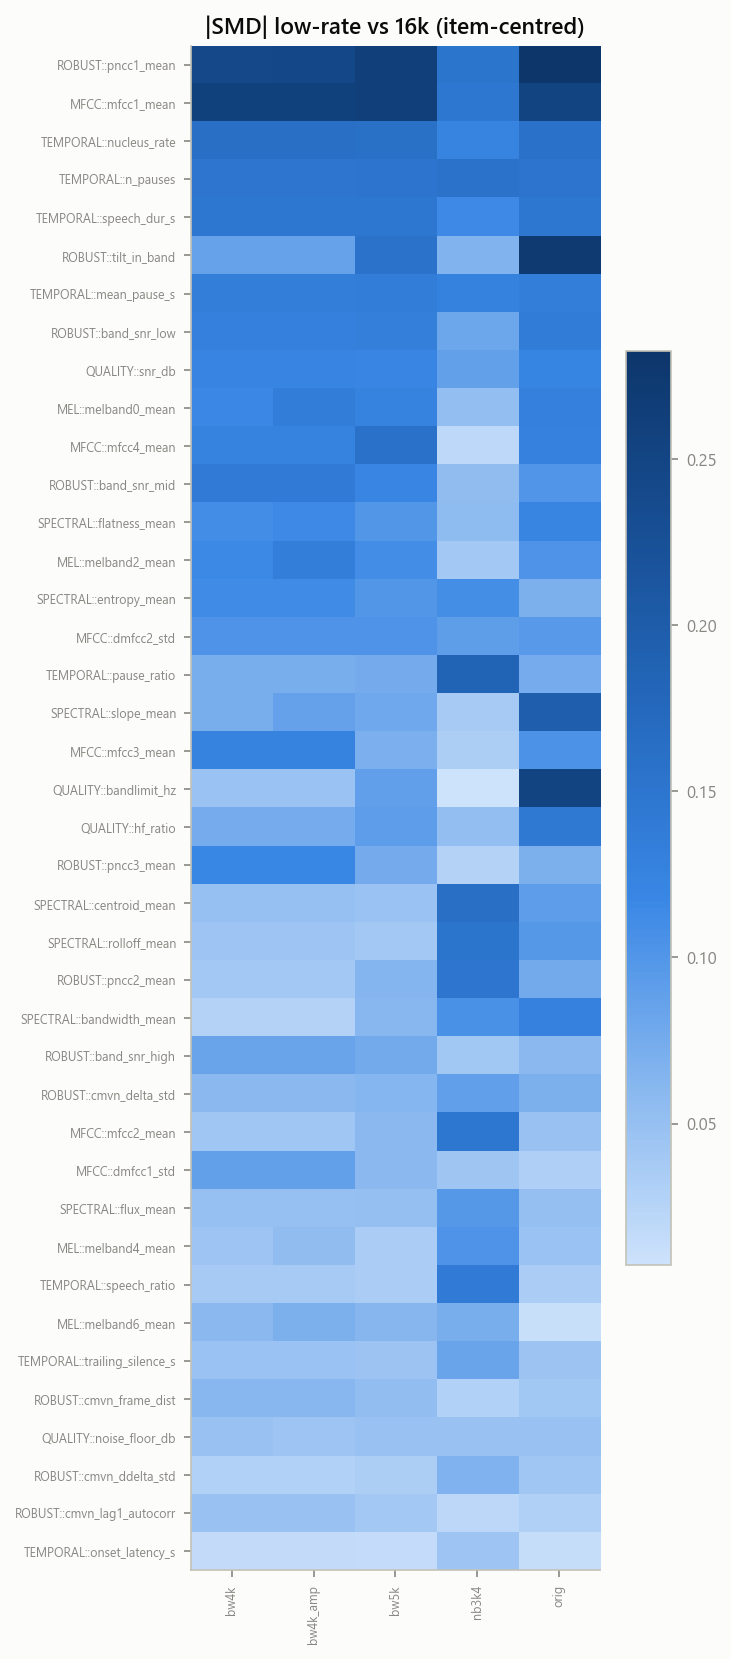

`domain_embedding_bw4k`

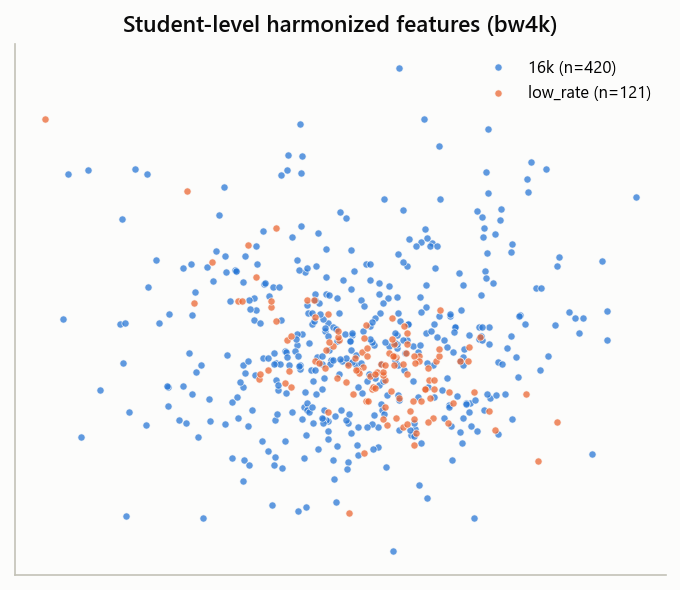

`domain_embedding_bw4k_amp`

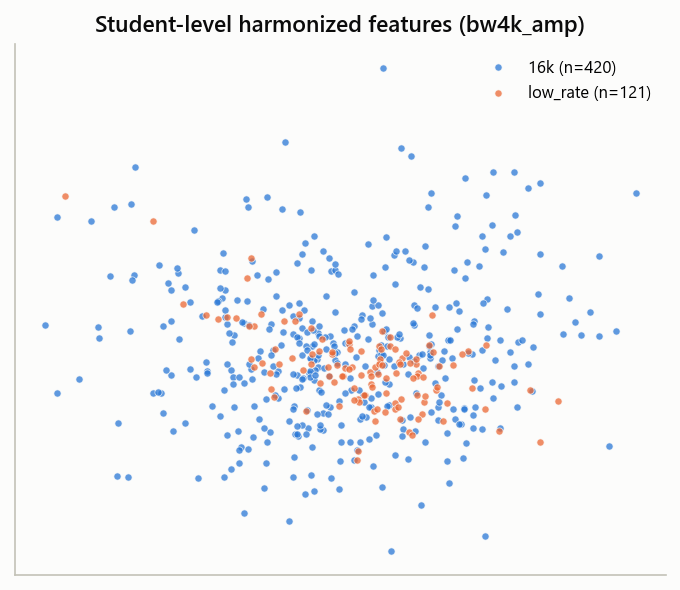

`domain_embedding_bw5k`

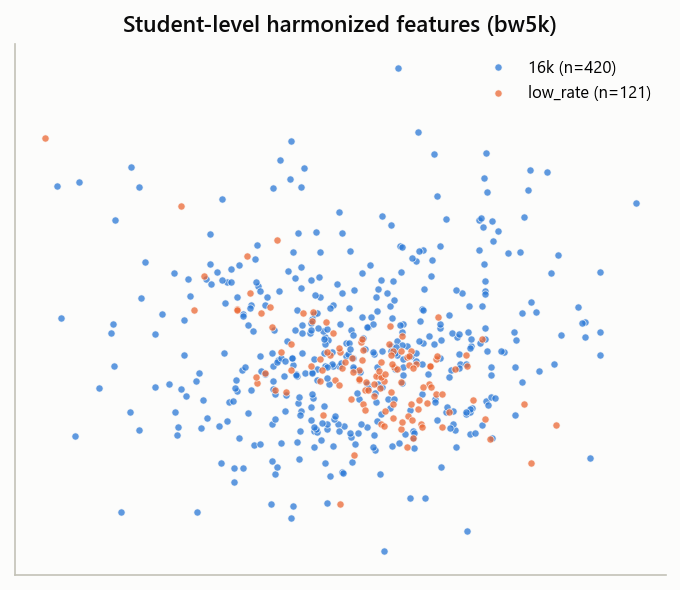

`domain_embedding_nb3k4`

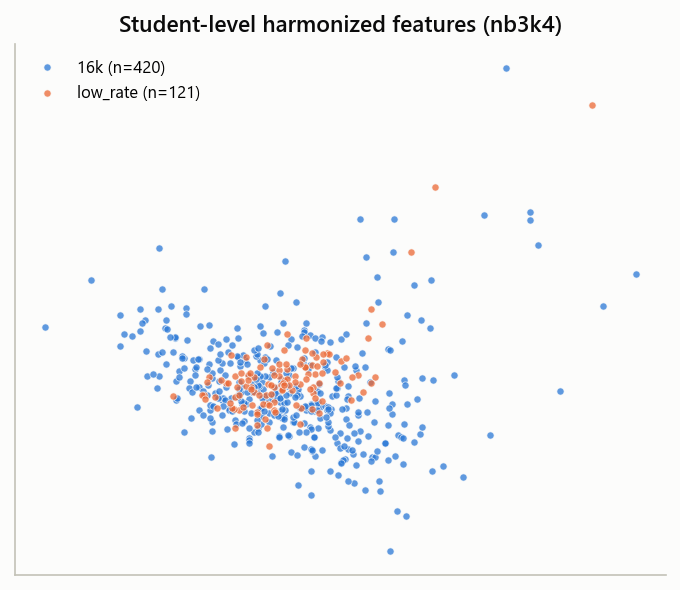

`domain_embedding_orig`

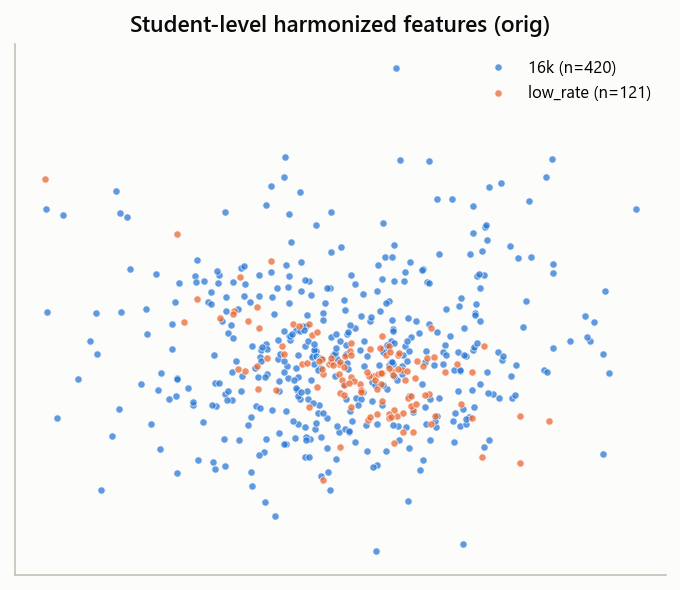

`equal_n_gap`

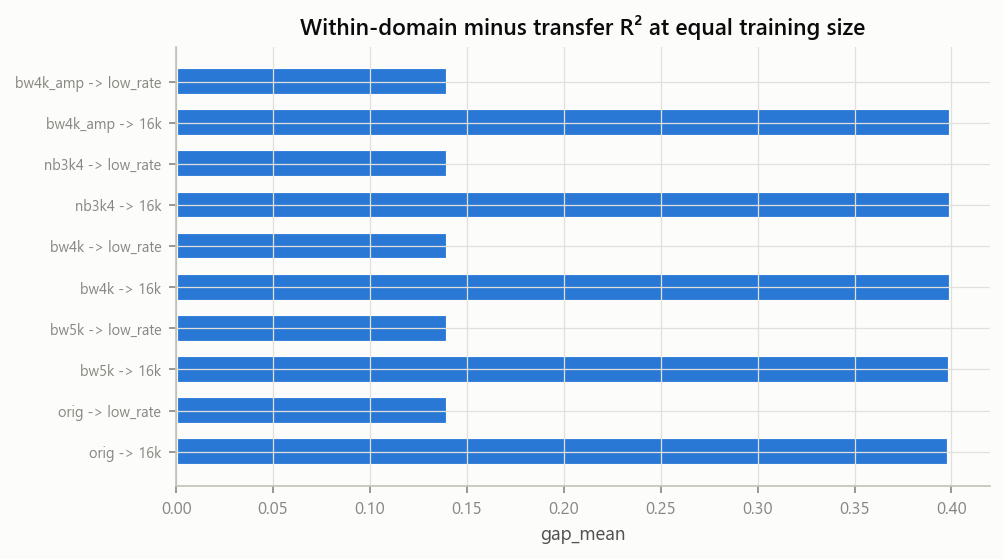

`feature_robustness_ranking`

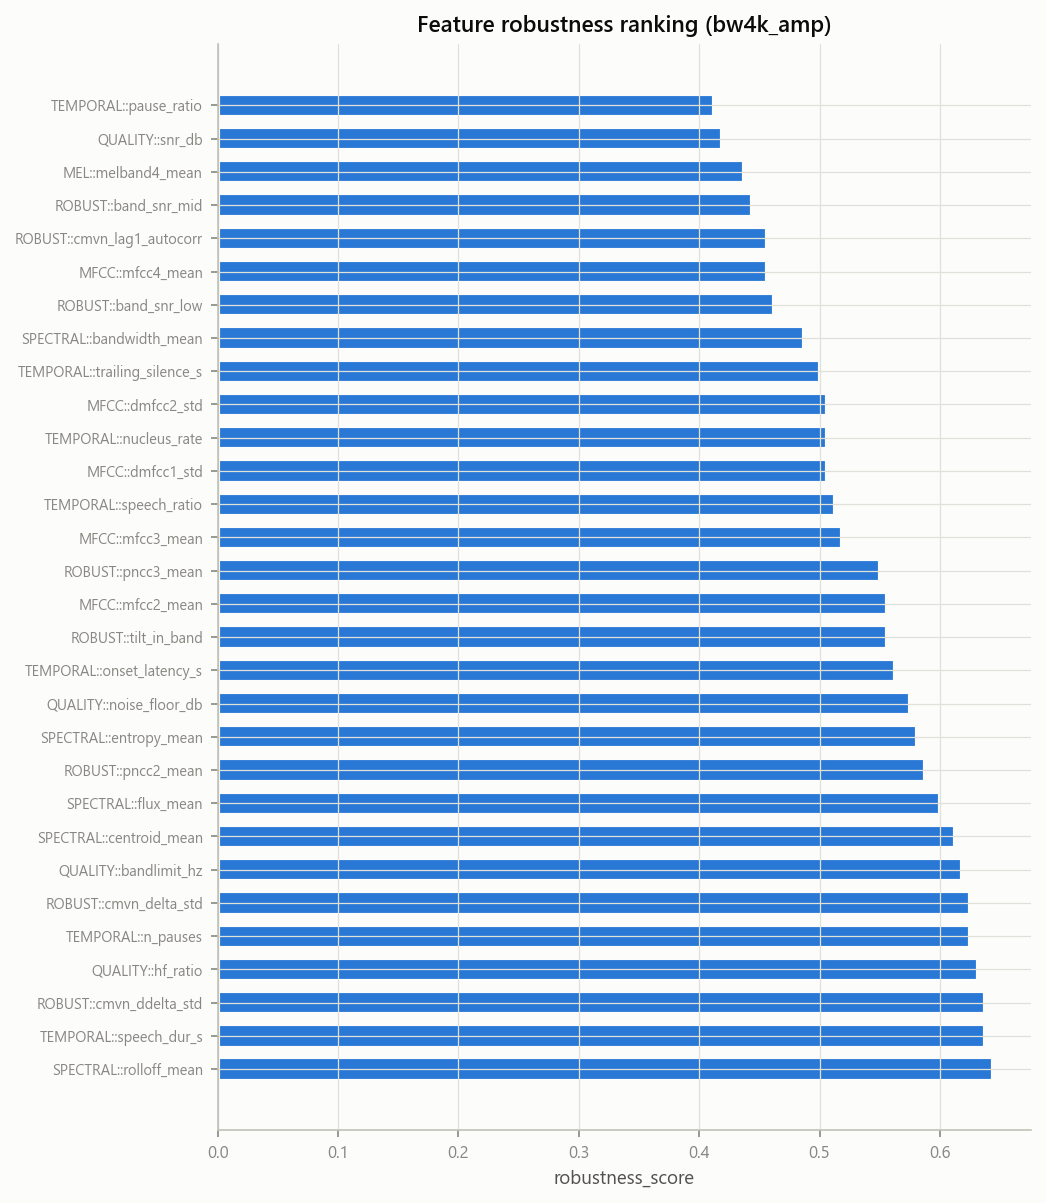

`incremental_r2_by_variant`

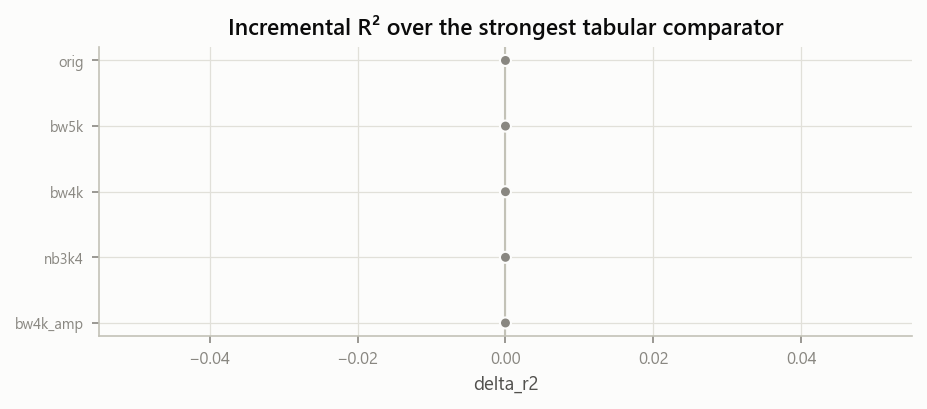

`sample_rate_separability`

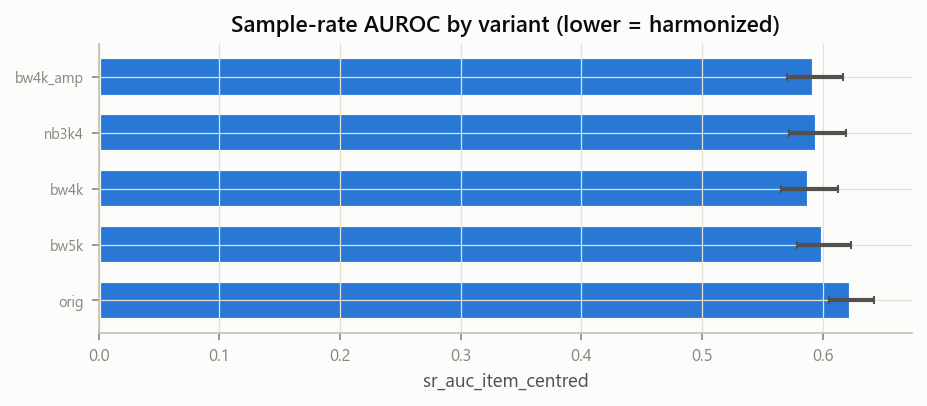

`spectra_by_domain`

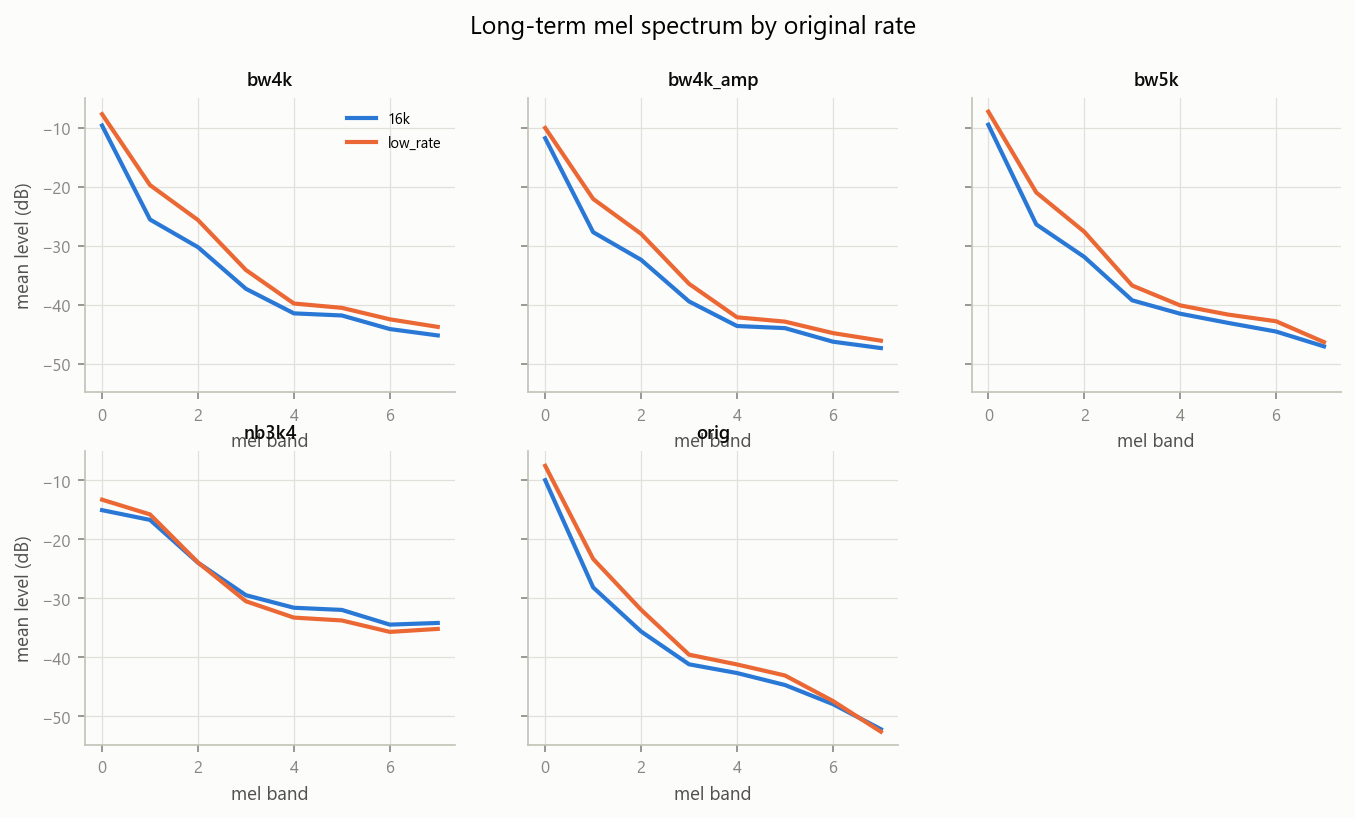

`stability_matrix_bw4k`

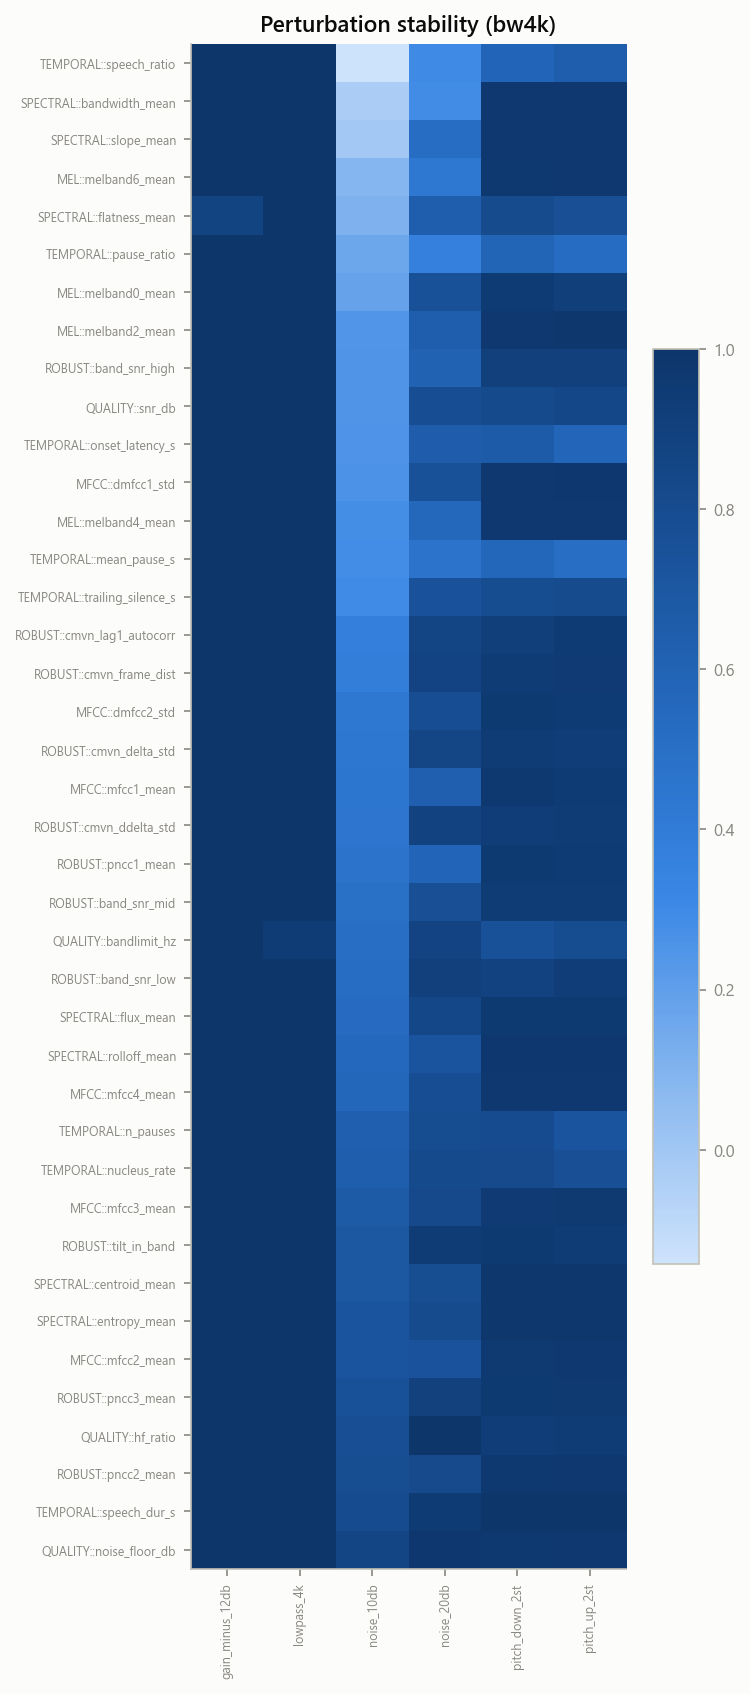

`stability_matrix_bw4k_amp`

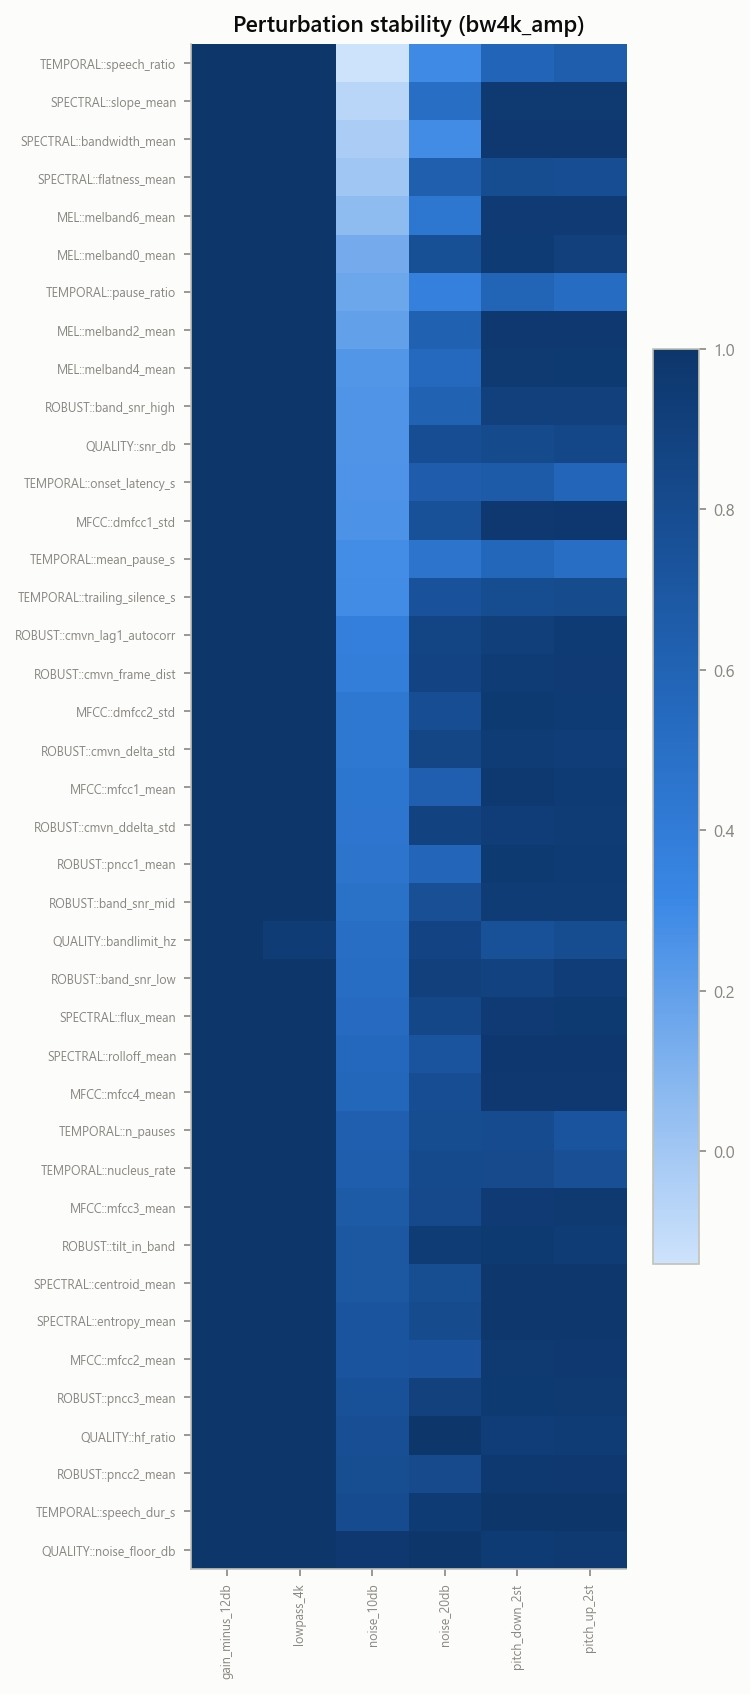

`stability_matrix_bw5k`

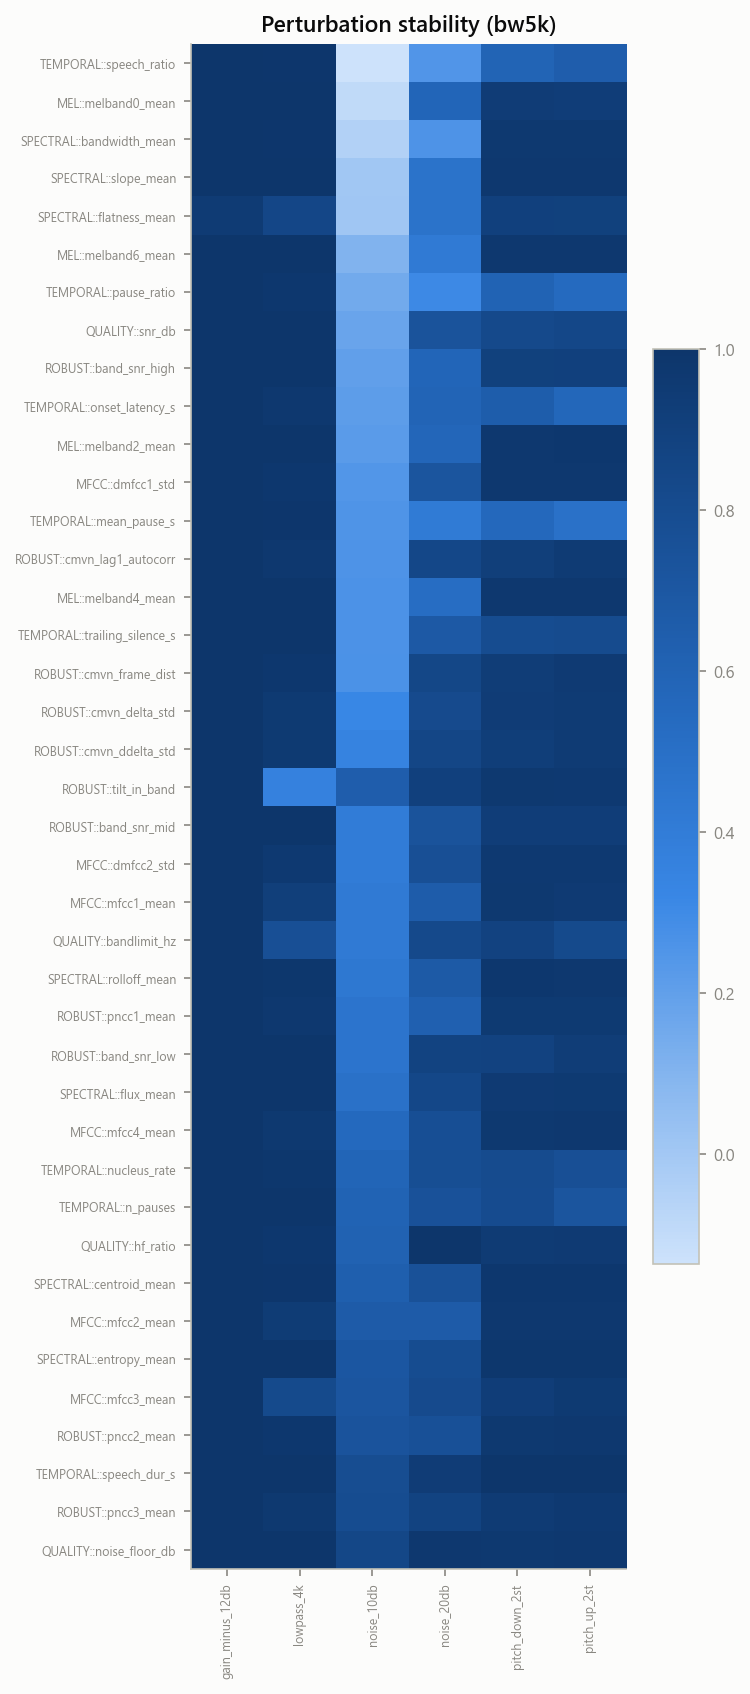

`stability_matrix_nb3k4`

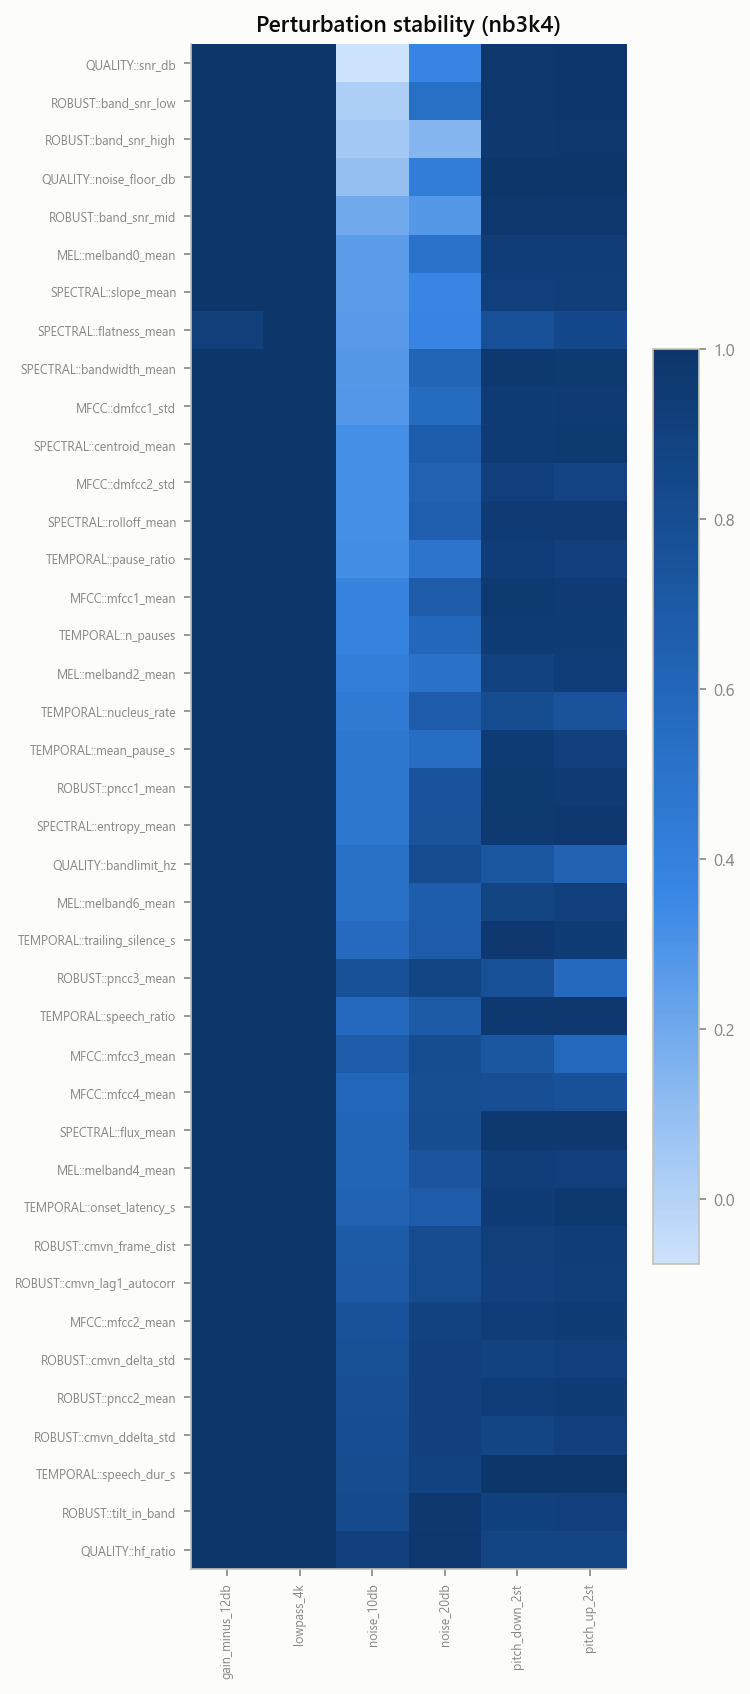

`stability_matrix_orig`

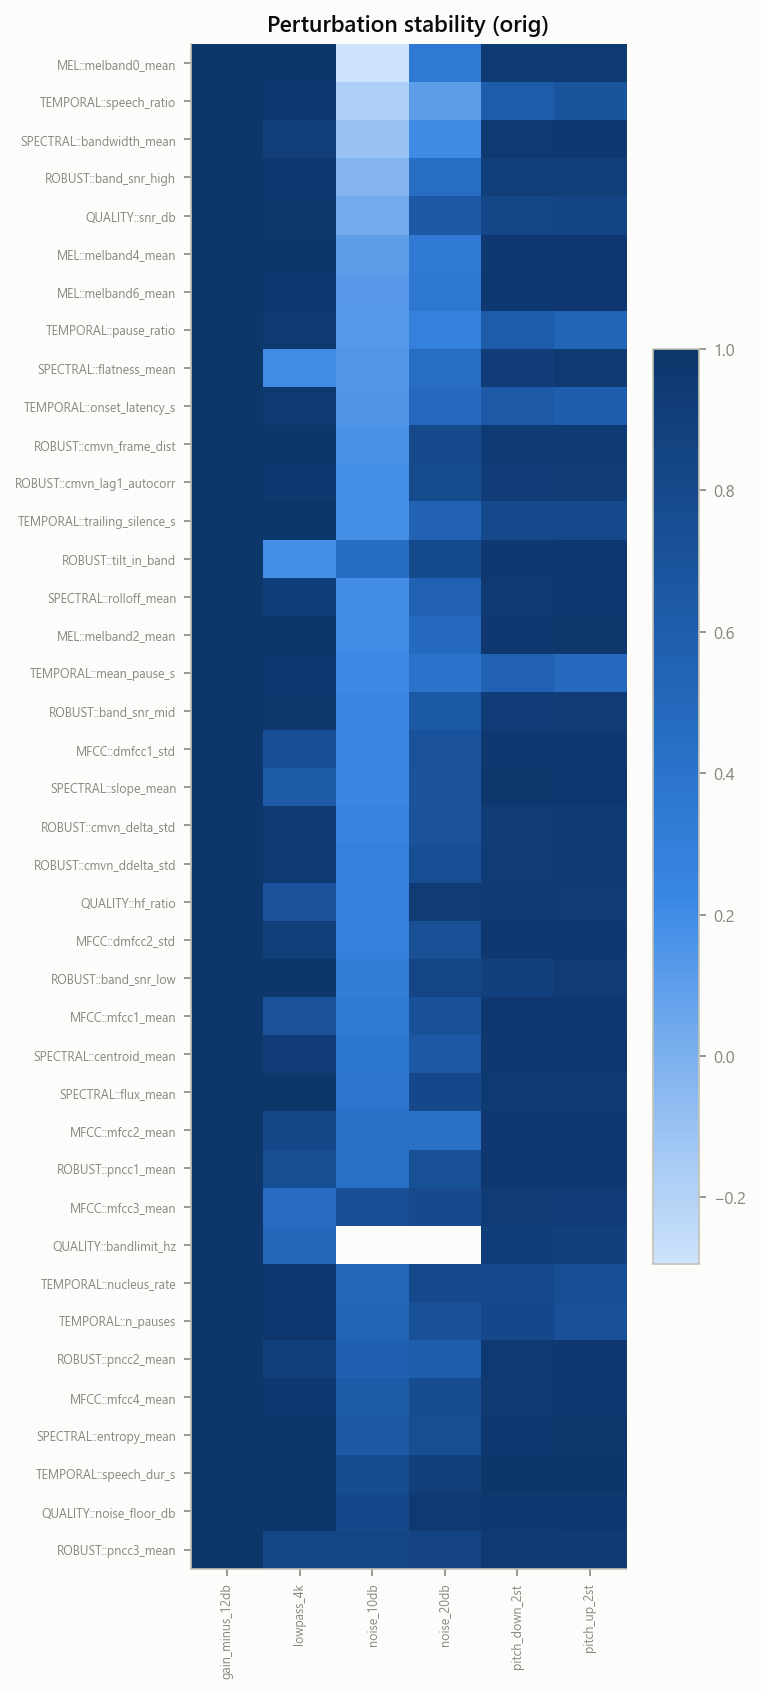

`transfer_by_direction`

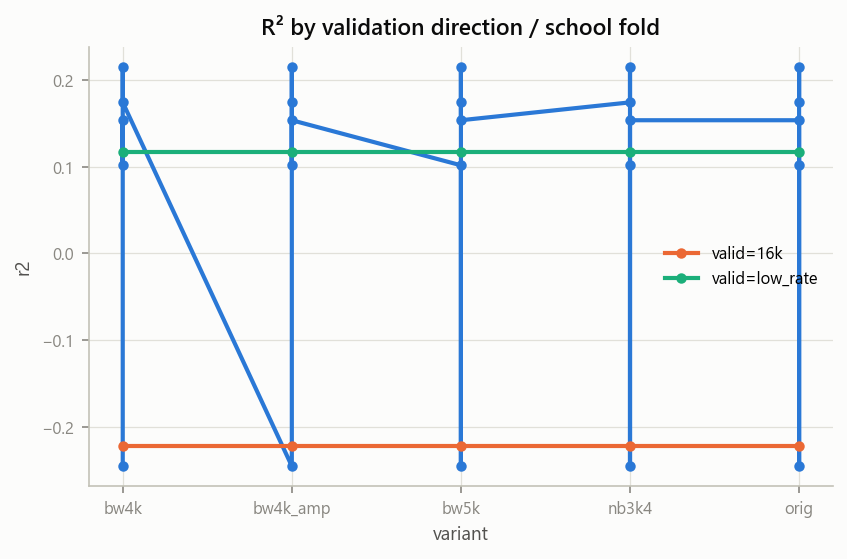

{
  "selected_variant": "bw4k_amp",
  "rule": "max incremental R2 among variants whose sample-rate AUROC <= orig AUROC; ties -> stability",
  "delta_r2": 0.0,
  "sr_auc_item_centred": 0.5927493878614409,
  "orig_sr_auc": 0.6236806186303413
}


In [24]:
if RUN_PIPELINE:
    display(run_stage(pipe, "P16", RUN["P16"], FORCE, RUN_LOG))
show_stage_v2(ctx, "P16", ["variant_summary", "student_results", "equal_n_transfer", "transfer_breakdown", "cpu_gpu_parity",
                           "feature_robustness_ranking"], TABLE_ROWS, SHOW_ALL_TABLES)
print(json.dumps(ctx.read_stage_json("P16", "selection", {}), indent=2))

---
## 6 · P17 — Clip-level correctness intelligence
Student-disjoint classifiers of `P(correct | audio, expected text, task)` for metadata-only, linguistic, temporal, spectral/MFCC, wavelet/pitch, harmonized, combined, phonetic and embedding feature sets. Nested cross-fitted probabilities become student-level soft-correctness features; their value is measured against the comparator **and** against metadata-only soft features (audio-specific information). Confidence is *not* a verified pronunciation-quality measure.

17:36:03 | INFO    | === P17 correctness — clip-level correctness intelligence (nested cross-fitting)
C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\src\wildspeech\validation\metrics.py:27: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per = oof.groupby("repeat").apply(lambda d: pd.Series(metric_row(d["y_true"], d["y_pred"])))
C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\src\wildspeech\diagnostics\scientific_validation.py:35: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explic

,stage,status,note
0,P00,cached,2026-11-20T14:09:49
1,P01,cached,2026-11-20T14:10:08
2,P16,cached,2026-11-20T17:31:21
3,P17,completed,1497.2s


### P17 · Clip-level correctness intelligence · `completed` · 1497s

,key,value
0,selected_set,COMBINED
1,model,LIGHTGBM
2,n_clip_models,28
3,sets,"[""META"", ""LINGUISTIC"", ""TEMPORAL"", ""SPECTRAL"",..."


**Findings (computed from this run's tables)**

- Best clip classifier: HARMONIZED / MLP AUROC 0.860, Brier 0.1525, ECE 0.0179.
- HARMONIZED: ΔAUROC over metadata-only 0.104 [0.095, 0.114] (student-block bootstrap).
- TEMPORAL: ΔAUROC over metadata-only 0.100 [0.090, 0.109] (student-block bootstrap).
- COMBINED: ΔAUROC over metadata-only 0.100 [0.090, 0.110] (student-block bootstrap).
- WAVELET_PITCH: ΔAUROC over metadata-only 0.077 [0.069, 0.085] (student-block bootstrap).
- SPECTRAL: ΔAUROC over metadata-only 0.073 [0.065, 0.081] (student-block bootstrap).
- LINGUISTIC: ΔAUROC over metadata-only 0.000 [-0.000, 0.001] (student-block bootstrap).
- Student level `P17_SOFTMETA`: R² 0.2153, Δ vs comparator 0.0000 [0.0000, 0.0000], Δ vs metadata-only soft features n/a [n/a, n/a].
- Student level `P17_SOFTMETA`: R² 0.1664, Δ vs comparator 0.0000 [0.0000, 0.0000], Δ vs metadata-only soft features n/a [n/a, n/a].
- Student level `P17_SOFTMETA`: R² -0.1334, Δ vs comparator 0.0000 [0.0000, 0.0000], Δ vs metadata-only soft features n/a [n/a, n/a].
- Student level `P17_SOFTMETA`: R² 0.0145, Δ vs comparator -0.0200 [-0.0426, 0.0010], Δ vs metadata-only soft features n/a [n/a, n/a].
- Student level `P17_SOFT_LINGUISTIC`: R² 0.2153, Δ vs comparator 0.0000 [0.0000, 0.0000], Δ vs metadata-only soft features 0.0000 [0.0000, 0.0000].
- Student level `P17_SOFT_LINGUISTIC`: R² 0.1664, Δ vs comparator 0.0000 [0.0000, 0.0000], Δ vs metadata-only soft features 0.0000 [0.0000, 0.0000].
- Student level `P17_SOFT_LINGUISTIC`: R² -0.1334, Δ vs comparator 0.0000 [0.0000, 0.0000], Δ vs metadata-only soft features 0.0000 [0.0000, 0.0000].
- Student level `P17_SOFT_LINGUISTIC`: R² 0.0288, Δ vs comparator -0.0057 [-0.0105, -0.0012], Δ vs metadata-only soft features 0.0143 [-0.0058, 0.0343].
- Student level `P17_SOFT_TEMPORAL`: R² 0.2153, Δ vs comparator 0.0000 [0.0000, 0.0000], Δ vs metadata-only soft features 0.0000 [0.0000, 0.0000].
- Student level `P17_SOFT_TEMPORAL`: R² 0.1664, Δ vs comparator 0.0000 [0.0000, 0.0000], Δ vs metadata-only soft features 0.0000 [0.0000, 0.0000].
- Student level `P17_SOFT_TEMPORAL`: R² -0.1334, Δ vs comparator 0.0000 [0.0000, 0.0000], Δ vs metadata-only soft features 0.0000 [0.0000, 0.0000].
- Student level `P17_SOFT_TEMPORAL`: R² 0.0345, Δ vs comparator 0.0000 [0.0000, 0.0000], Δ vs metadata-only soft features 0.0200 [-0.0010, 0.0426].
- Student level `P17_SOFT_HARMONIZED`: R² 0.2153, Δ vs comparator 0.0000 [0.0000, 0.0000], Δ vs metadata-only soft features 0.0000 [0.0000, 0.0000].
- Student level `P17_SOFT_HARMONIZED`: R² 0.1664, Δ vs comparator 0.0000 [0.0000, 0.0000], Δ vs metadata-only soft features 0.0000 [0.0000, 0.0000].
- Student level `P17_SOFT_HARMONIZED`: R² -0.1334, Δ vs comparator 0.0000 [0.0000, 0.0000], Δ vs metadata-only soft features 0.0000 [0.0000, 0.0000].
- Student level `P17_SOFT_HARMONIZED`: R² 0.0345, Δ vs comparator 0.0000 [0.0000, 0.0000], Δ vs metadata-only soft features 0.0200 [-0.0010, 0.0426].
- Student level `P17_SOFT_COMBINED`: R² 0.2153, Δ vs comparator 0.0000 [0.0000, 0.0000], Δ vs metadata-only soft features 0.0000 [0.0000, 0.0000].
- Student level `P17_SOFT_COMBINED`: R² 0.1664, Δ vs comparator 0.0000 [0.0000, 0.0000], Δ vs metadata-only soft features 0.0000 [0.0000, 0.0000].
- Student level `P17_SOFT_COMBINED`: R² -0.1334, Δ vs comparator 0.0000 [0.0000, 0.0000], Δ vs metadata-only soft features 0.0000 [0.0000, 0.0000].
- Student level `P17_SOFT_COMBINED`: R² 0.0345, Δ vs comparator 0.0000 [0.0000, 0.0000], Δ vs metadata-only soft features 0.0200 [-0.0010, 0.0426].
- Classification confidence is a learned summary, not a verified pronunciation-quality measure.

**clip_metrics** — 28 rows × 11 cols

... (18 outputs left out)

,stage,upstream,kind,status,stale,recorded_fingerprint,finished
0,P17,P16,hard,completed,False,0589839a6e987e33,2026-11-20T17:31:21
1,P17,P18,soft,never_run,NaN,NaN,NaN
2,P17,P20,soft,never_run,NaN,NaN,NaN
3,P17,P10,soft,completed,False,69df870789d6258c,2026-11-20T15:29:06


**validation_registry_summary** — 78 rows × 7 cols

,scheme,repeat,fold,label,n_train,n_valid,overlap
0,repeated_kfold,0,0,NaN,432,109,0
1,repeated_kfold,0,1,NaN,433,108,0
2,repeated_kfold,0,2,NaN,433,108,0
3,repeated_kfold,0,3,NaN,433,108,0
4,repeated_kfold,0,4,NaN,433,108,0
5,repeated_kfold,1,0,NaN,432,109,0
6,repeated_kfold,1,1,NaN,433,108,0
7,repeated_kfold,1,2,NaN,433,108,0
8,repeated_kfold,1,3,NaN,433,108,0
9,repeated_kfold,1,4,NaN,433,108,0


`audio_specific_gain`

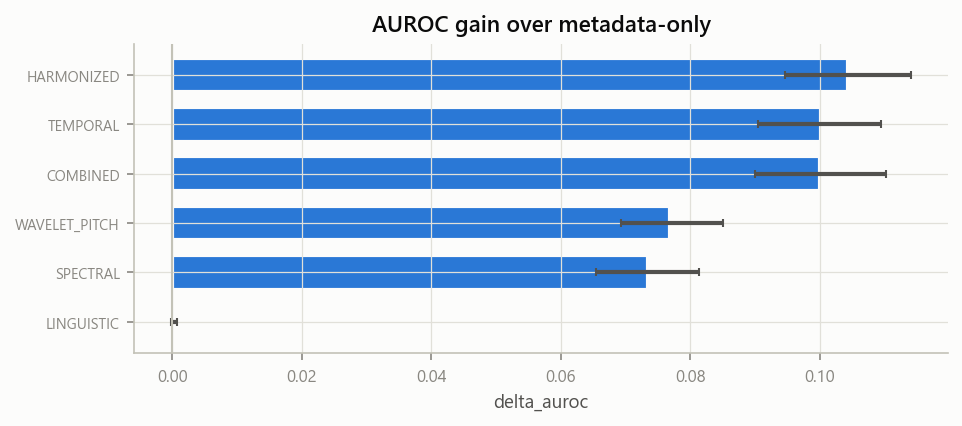

`calibration_isotonic`

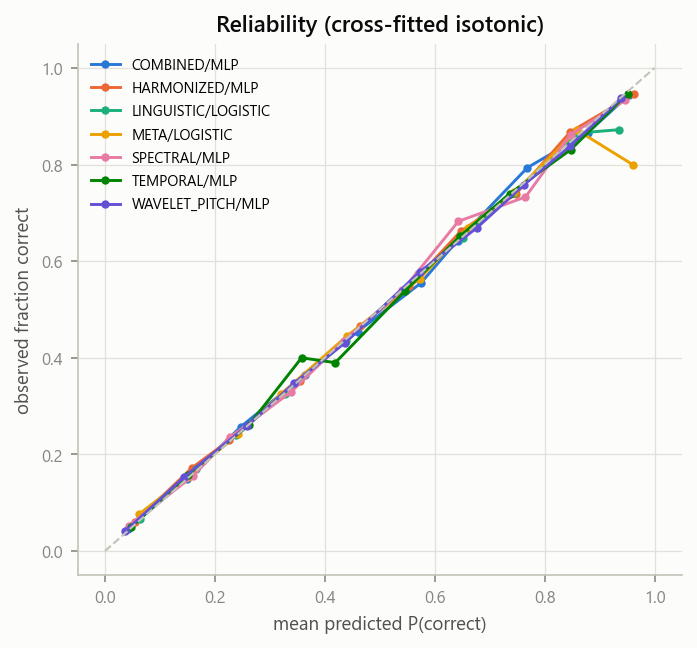

`calibration_raw`

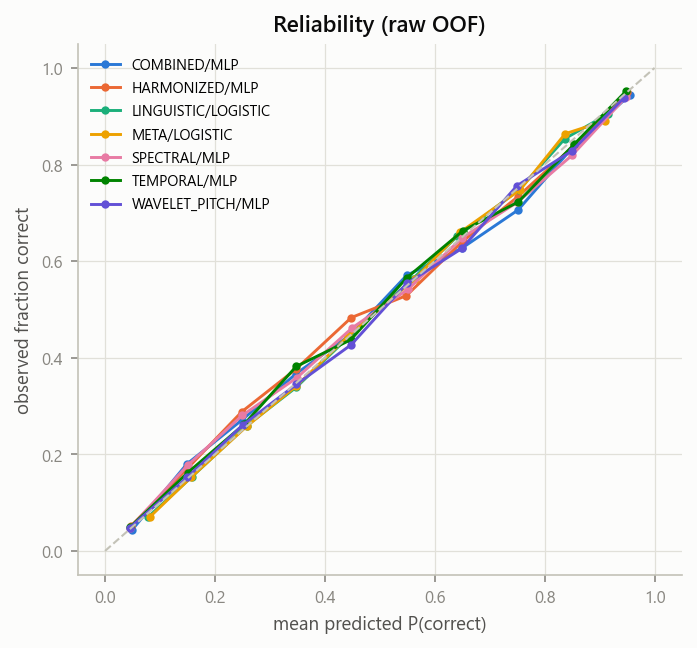

`confusion_by_task`

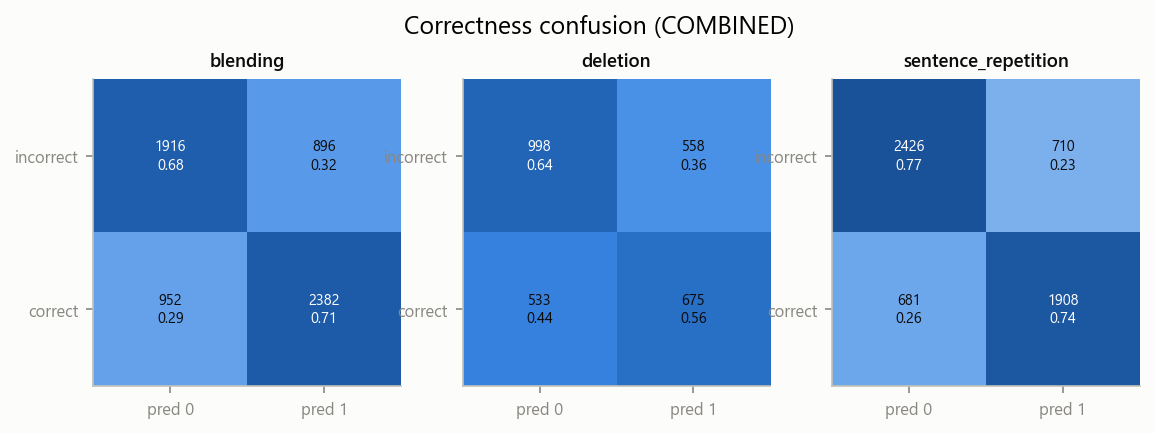

`pr_curves_incorrect`

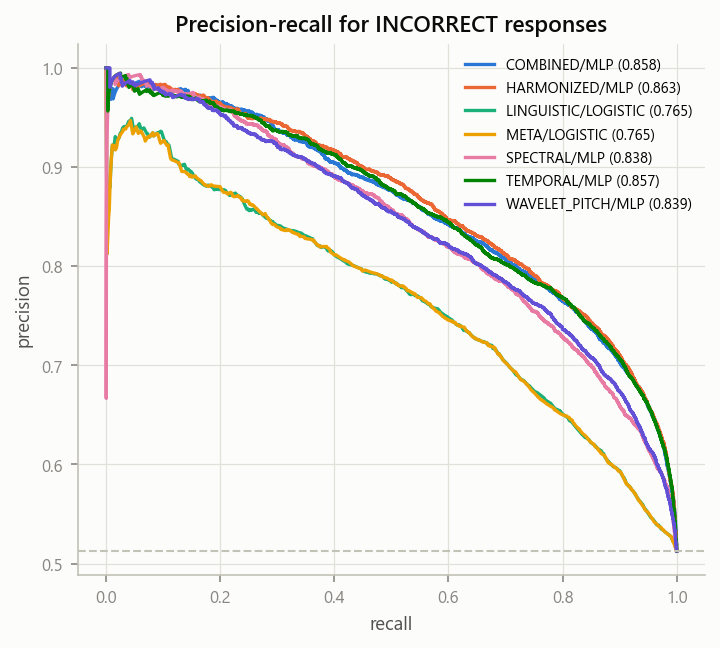

`residual_vs_top_soft_feature`

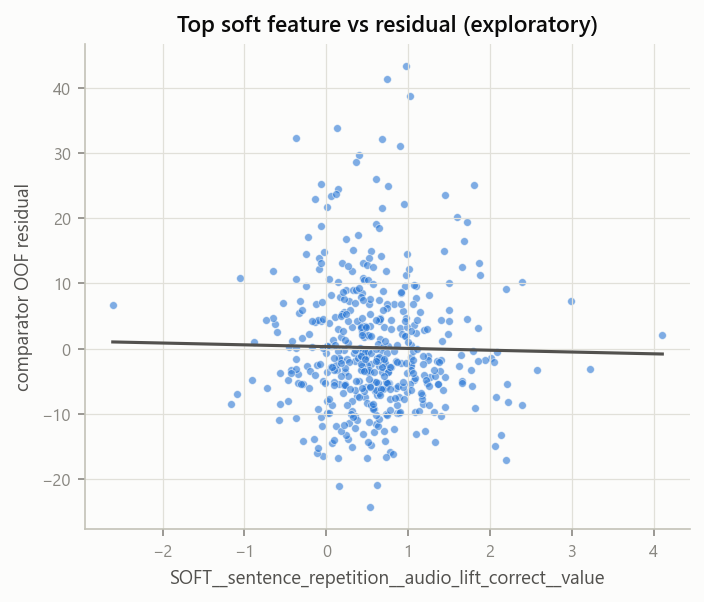

`roc_curves`

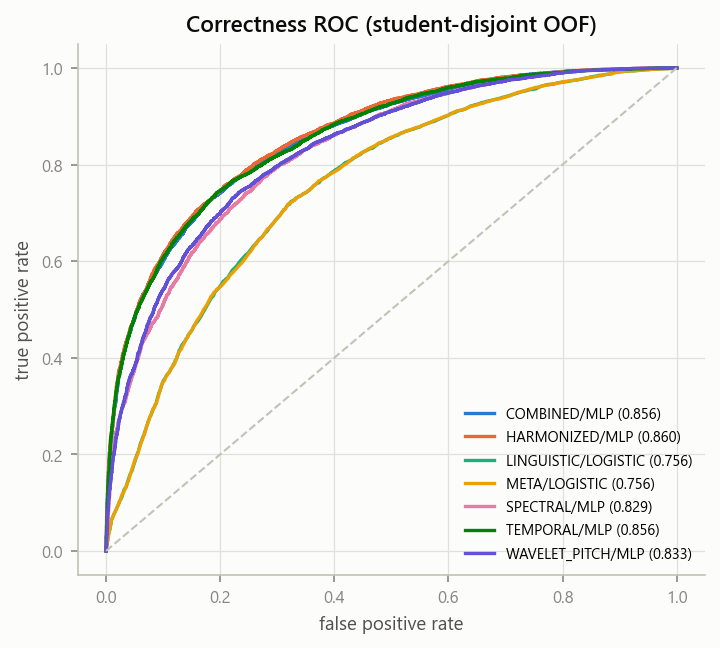

`soft_correctness_distributions`

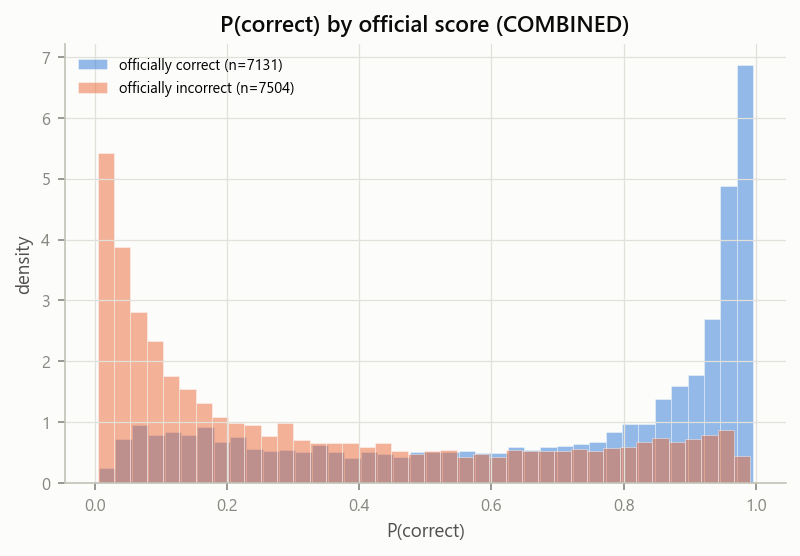

`student_incremental_r2`

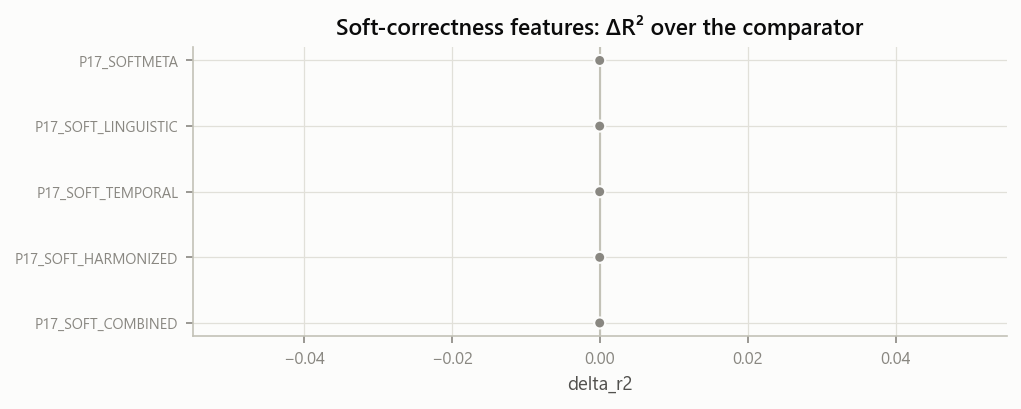

**Task-specific and domain-specific AUROC**

group_col              instrument        orig_rate              task                             
group                       ktea3    wj4       16k low_rate blending deletion sentence_repetition
feature_set   model                                                                              
COMBINED      LIGHTGBM      0.825 0.7355      0.76   0.8416   0.7844   0.6452              0.8443
              LOGISTIC     0.8772  0.813    0.8322   0.8931   0.8435   0.7096               0.905
              MLP          0.8801 0.8167     0.838   0.8895   0.8482   0.7195              0.9046
              XGBOOST      0.8673 0.7818    0.8108   0.8772   0.8244   0.6982              0.8858
HARMONIZED    LIGHTGBM     0.8103 0.7263    0.7462   0.8332   0.7707   0.6352              0.8334
              LOGISTIC     0.8794  0.812    0.8337   0.8935   0.8455   0.7077               0.906
              MLP          0.8838 0.8222    0.8433   0.8925   0.8512   0.7347              0.9065
              XGBOOST      0.8617 0.7701     0.801   0.8733   0.8143   0.6894              0.8796
LINGUISTIC    LIGHTGBM     0.6623 0.6369    0.6219   0.6837   0.6221   0.5638              0.7112
              LOGISTIC     0.7693  0.733    0.7309   0.7611   0.7249   0.6894              0.7937
              MLP          0.7682 0.7331    0.7305   0.7614   0.7248   0.6876               0.792
              XGBOOST      0.7094 0.6562    0.6537   0.7107   0.6419   0.6245              0.7288
META          LIGHTGBM     0.6723 0.6464    0.6339    0.688   0.6375   0.5712              0.7131
              LOGISTIC     0.7691 0.7326    0.7305   0.7621   0.7248    0.689              0.7931
              MLP          0.7672  0.732    0.7287   0.7605   0.7218   0.6864               0.793
              XGBOOST      0.7072 0.6511    0.6486    0.706   0.6425   0.6247              0.7198
SPECTRAL      LIGHTGBM     0.7442 0.6966     0.694   0.7699    0.686   0.6053              0.8051
              LOGISTIC     0.8323  0.786     0.792   0.8576   0.7745   0.6865              0.8893
              MLP          0.8454 0.8028     0.811   0.8554    0.792   0.7263              0.8932
              XGBOOST       0.804 0.7401    0.7487     0.82   0.7265   0.6624              0.8545
TEMPORAL      LIGHTGBM     0.7855 0.7092    0.7226   0.8101   0.7423   0.6148              0.8167
              LOGISTIC     0.8695 0.8035    0.8236   0.8836   0.8387   0.7034              0.8964
              MLP          0.8804  0.817    0.8372   0.8931   0.8437   0.7222              0.9065
              XGBOOST      0.8425 0.7472     0.776   0.8582    0.792    0.665              0.8603
WAVELET_PITCH LIGHTGBM     0.7431 0.7015    0.6968   0.7694   0.6977   0.6058              0.7978
              LOGISTIC     0.8197 0.7755    0.7802   0.8383   0.7682   0.6701              0.8785
              MLP          0.8474 0.8103     0.816   0.8583   0.8014   0.7256              0.8922
              XGBOOST      0.8072 0.7441    0.7539   0.8189   0.7487   0.6651              0.8431

In [25]:
if RUN_PIPELINE:
    display(run_stage(pipe, "P17", RUN["P17"], FORCE, RUN_LOG))
show_stage_v2(ctx, "P17", ["clip_metrics", "audio_specific_gain", "domain_transfer_auc", "student_soft_results",
                           "student_residual_associations", "feature_bank"], TABLE_ROWS, SHOW_ALL_TABLES)
byg = ctx.read_stage_table("P17", "clip_metrics_by_group")
if byg is not None and not byg.empty:
    display(Markdown("**Task-specific and domain-specific AUROC**"))
    display(byg.pivot_table(index=["feature_set", "model"], columns=["group_col", "group"], values="auroc"))

---
## 7 · P18 — Phonetic analysis
Whisper / wav2vec2 CTC / CTC phoneme recognition / forced alignment / G2P — only what the eligible models and metadata support. Blending, deletion and sentence repetition are analysed separately; the key question is variation **among officially correct responses**.

In [26]:
if RUN_PIPELINE:
    display(run_stage(pipe, "P18", RUN["P18"], FORCE, RUN_LOG))
show_stage_v2(ctx, "P18", ["model_eligibility", "g2p_backend", "phonetic_run_summary", "correct_vs_incorrect",
                           "within_correct_profile", "within_correct_association", "student_results"], TABLE_ROWS, SHOW_ALL_TABLES)

18:02:47 | INFO    | === P18 phonetics — content-conditioned phonetic analysis (ASR / CTC / forced alignment / G2P)


C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\src\wildspeech\registry.py:53: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  merged = pd.concat([old_i, fresh], axis=0).reset_index()
C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\src\wildspeech\registry.py:53: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  merged = pd.concat([old_i, fresh], axis=0).reset_index()


,stage,status,note
0,P00,cached,2026-11-20T14:09:49
1,P01,cached,2026-11-20T14:10:08
2,P18,completed,0.2s


### P18 · Phonetic and linguistic intelligence · `completed` · 0s

,key,value
0,status,unavailable
1,reason,no eligible phonetic model; see model_eligibility


**Findings (computed from this run's tables)**

- 0 of 4 configured phonetic models were eligible (license + overlap verified).

... (4 outputs left out)

**upstream_lineage** — 1 rows × 7 cols

,stage,upstream,kind,status,stale,recorded_fingerprint,finished
0,P18,P01,hard,completed,False,db6cc262f70018a7,2026-11-20T14:10:08


**validation_registry_summary** — 78 rows × 7 cols

,scheme,repeat,fold,label,n_train,n_valid,overlap
0,repeated_kfold,0,0,NaN,432,109,0
1,repeated_kfold,0,1,NaN,433,108,0
2,repeated_kfold,0,2,NaN,433,108,0
3,repeated_kfold,0,3,NaN,433,108,0
4,repeated_kfold,0,4,NaN,433,108,0
5,repeated_kfold,1,0,NaN,432,109,0
6,repeated_kfold,1,1,NaN,433,108,0
7,repeated_kfold,1,2,NaN,433,108,0
8,repeated_kfold,1,3,NaN,433,108,0
9,repeated_kfold,1,4,NaN,433,108,0


---
## 8 · P19 — Reference-conditioned speech
Every recording is compared with exemplars of *correct* responses to the same expected word/sentence from training-fold students (nested so a student never shapes their own reference): MFCC / mel DTW, duration-normalised and localized deviation, warping consistency, posterior and embedding similarity, CTC likelihood.

18:02:59 | INFO    | === P19 reference — reference-conditioned speech modelling (templates, DTW, similarity)


P19 sequences train: 100%|██████████| 14704/14704 [00:58<00:00, 252.28clip/s, clips/s=252.3, RAM=0.6G, VRAM=9.8/9.8G, fail=0, ckpt=shard-20261120-180358-00014.npz]        
C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\src\wildspeech\validation\metrics.py:27: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per = oof.groupby("repeat").apply(lambda d: pd.Series(metric_row(d["y_true"], d["y_pred"])))
C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\src\wildspeech\diagnostics\scientific_validation.py:35: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation.

,stage,status,note
0,P00,cached,2026-11-20T14:09:49
1,P01,cached,2026-11-20T14:10:08
2,P16,cached,2026-11-20T17:31:21
3,P19,completed,1347.8s


### P19 · Reference-conditioned speech modelling · `completed` · 1348s

,key,value
0,status,ok
1,variant,bw4k_amp
2,n_clips_scored,13714
3,features,"[""dtw_mfcc_mean"", ""dtw_mfcc_min"", ""dtw_mel_mea..."


**Findings (computed from this run's tables)**

- Strongest reference deviation for correctness: local_dev_max (|AUROC−0.5|·2 = 0.410).
- Deviation among correct responses vs comparator residuals: 0 confirmatory associations at FDR q < 0.05.
- `P19_REF`: R² 0.2153, Δ vs comparator 0.0000 [0.0000, 0.0000].

... (15 outputs left out)

,stage,upstream,kind,status,stale,recorded_fingerprint,finished
0,P19,P16,hard,completed,False,0589839a6e987e33,2026-11-20T17:31:21
1,P19,P18,soft,completed,False,2121d8adde3bd95e,2026-11-20T18:02:47
2,P19,P20,soft,never_run,NaN,NaN,NaN


**validation_registry_summary** — 78 rows × 7 cols

,scheme,repeat,fold,label,n_train,n_valid,overlap
0,repeated_kfold,0,0,NaN,432,109,0
1,repeated_kfold,0,1,NaN,433,108,0
2,repeated_kfold,0,2,NaN,433,108,0
3,repeated_kfold,0,3,NaN,433,108,0
4,repeated_kfold,0,4,NaN,433,108,0
5,repeated_kfold,1,0,NaN,432,109,0
6,repeated_kfold,1,1,NaN,433,108,0
7,repeated_kfold,1,2,NaN,433,108,0
8,repeated_kfold,1,3,NaN,433,108,0
9,repeated_kfold,1,4,NaN,433,108,0


`deviation_distribution_dtw_mel_mean`

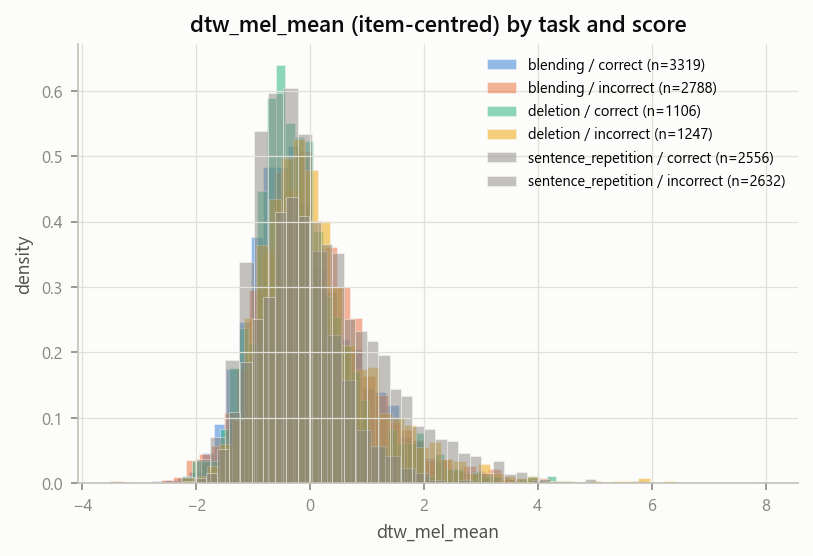

`deviation_distribution_dtw_mfcc_mean`

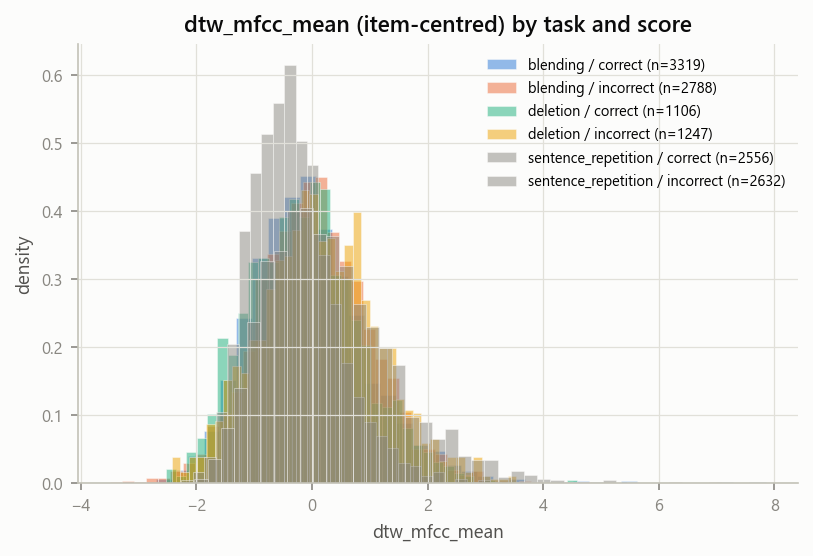

`deviation_distribution_dtw_mfcc_min`

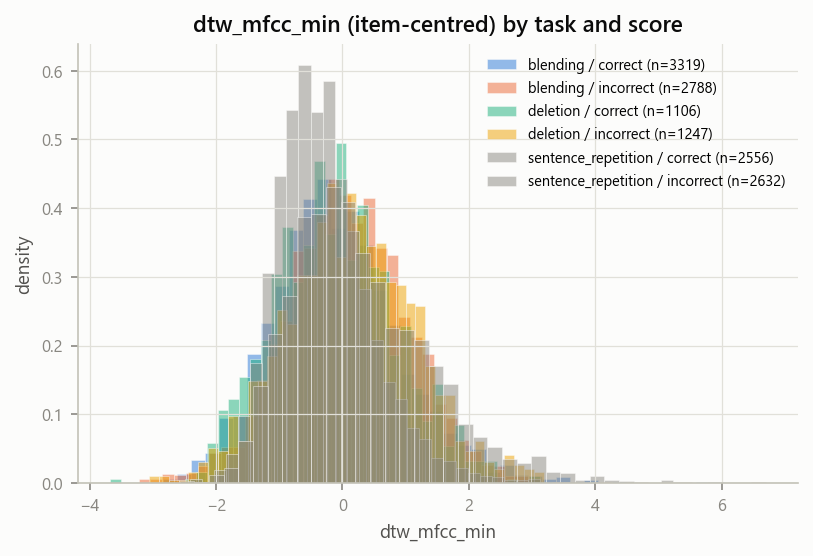

`deviation_distribution_local_dev_max`

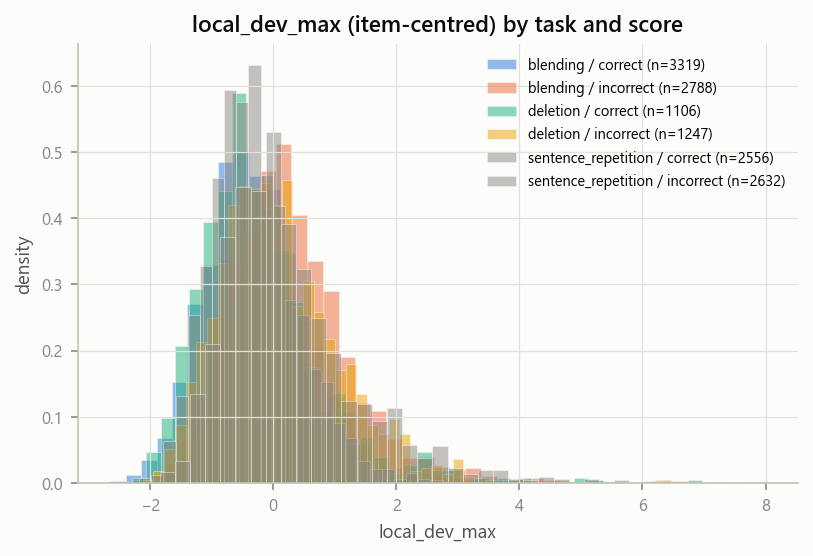

`dtw_alignment_examples`

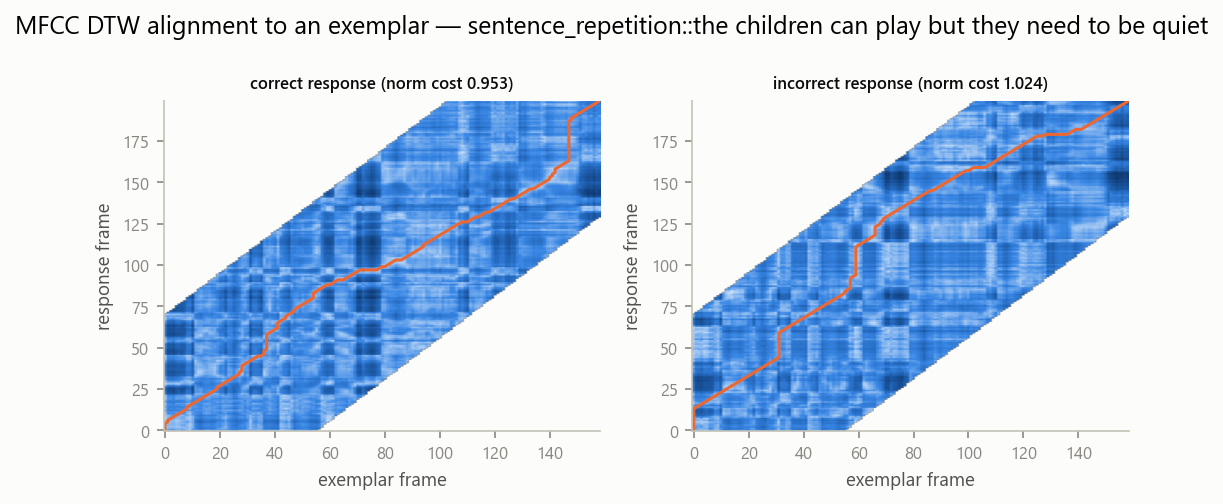

`item_reference_atlas`

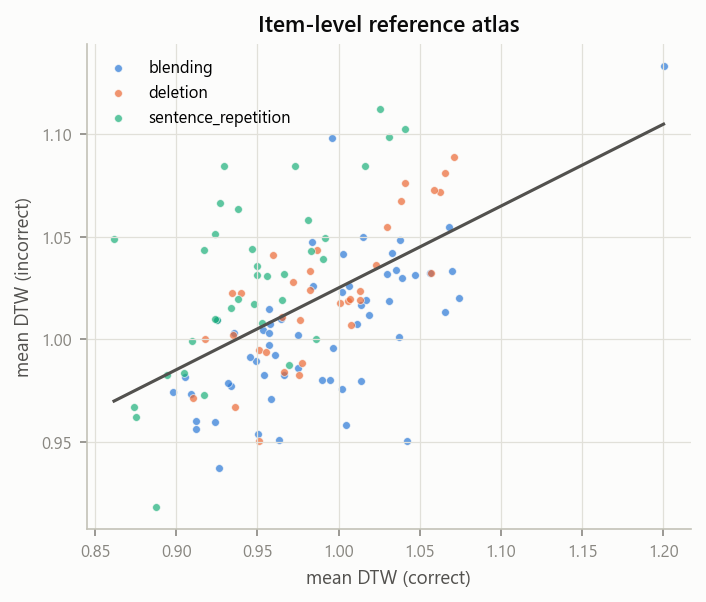

`residual_vs_top_deviation`

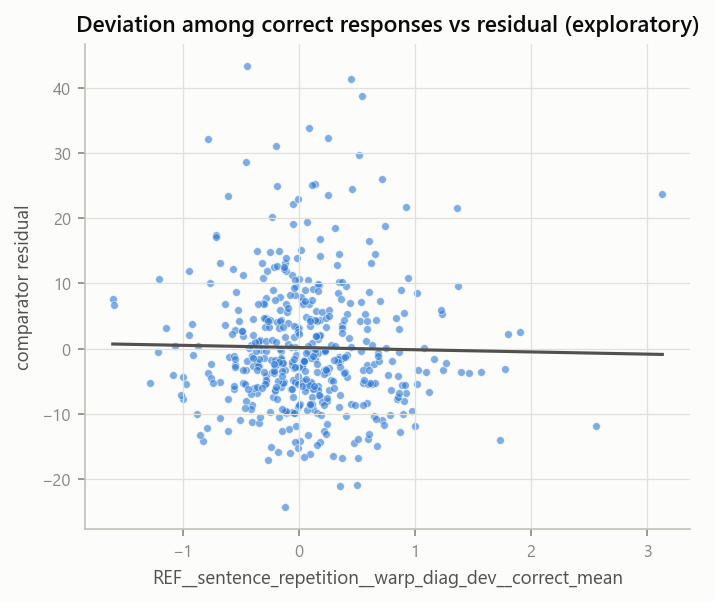

`similarity_matrix`

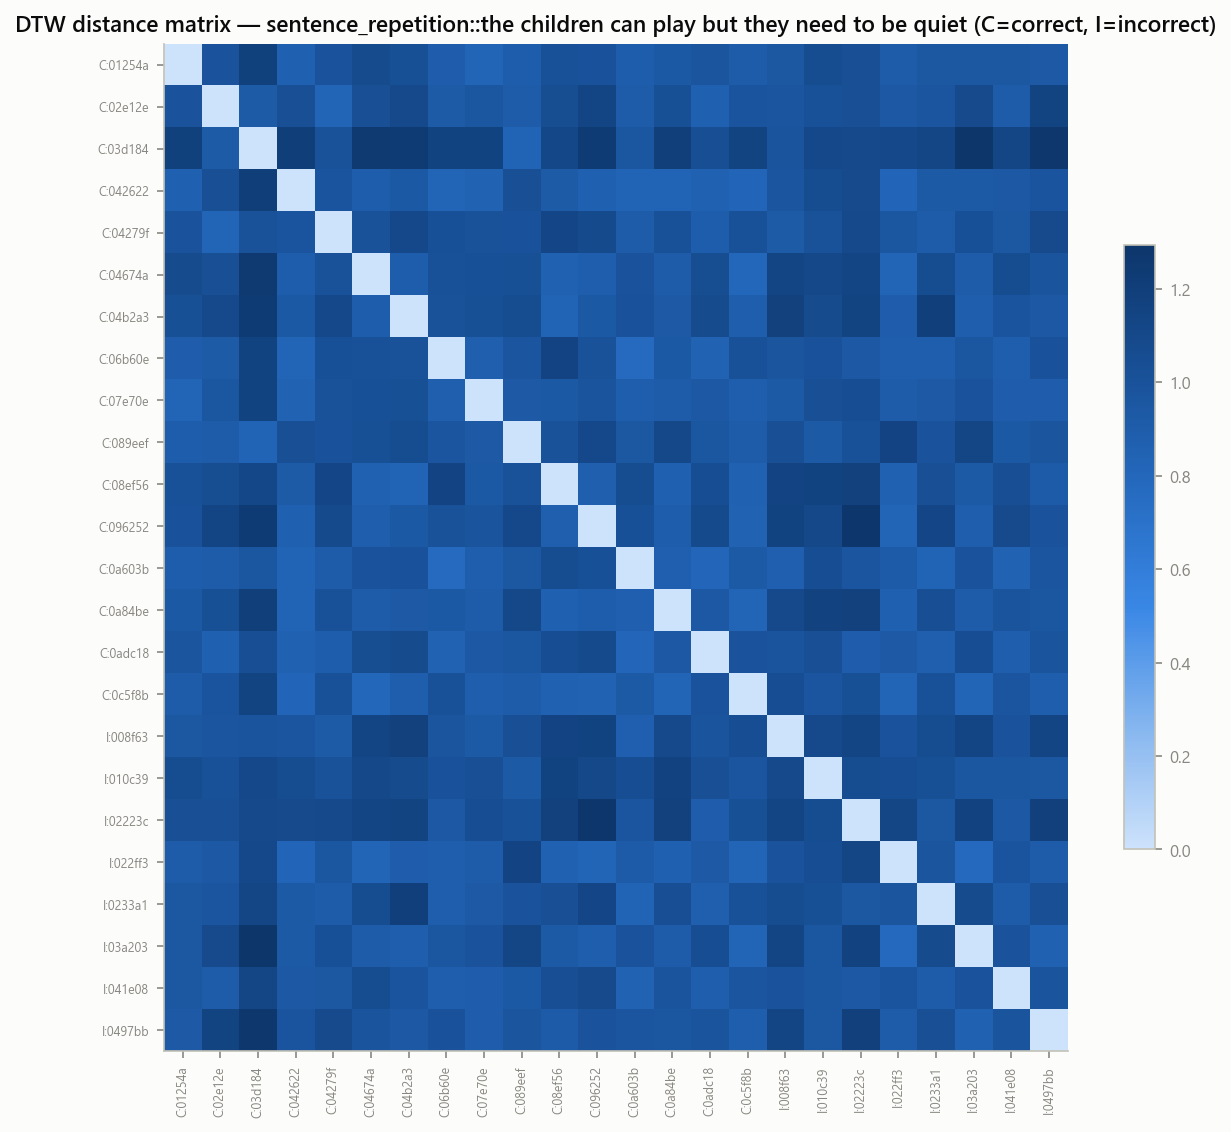

In [27]:
if RUN_PIPELINE:
    display(run_stage(pipe, "P19", RUN["P19"], FORCE, RUN_LOG))
show_stage_v2(ctx, "P19", ["reference_sources", "reference_clip_auc", "within_correct_association", "adjusted_associations",
                           "student_results", "item_reference_atlas"], TABLE_ROWS, SHOW_ALL_TABLES)

---
## 9 · P20 — Foundation models
Frozen wav2vec2 / HuBERT / WavLM / Whisper (and eligible child-speech) encoders: every layer, mean / std / speech-masked pooling, float16 shards. Layer discovery for correctness, phonetic content and domain robustness, then compact (fold-fitted) student representations — never thousands of raw statistics.

In [28]:
if RUN_PIPELINE:
    display(run_stage(pipe, "P20", RUN["P20"], FORCE, RUN_LOG))
show_stage_v2(ctx, "P20", ["model_eligibility", "extraction_performance", "layer_metrics", "compression_comparison",
                           "student_results"], TABLE_ROWS, SHOW_ALL_TABLES)
print(json.dumps(ctx.read_stage_json("P20", "selection", {}), indent=2))

18:25:58 | INFO    | === P20 embeddings_v2 — frozen speech foundation-model representations, layer discovery


C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\src\wildspeech\registry.py:53: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  merged = pd.concat([old_i, fresh], axis=0).reset_index()
C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\src\wildspeech\registry.py:53: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  merged = pd.concat([old_i, fresh], axis=0).reset_index()


,stage,status,note
0,P00,cached,2026-11-20T14:09:49
1,P01,cached,2026-11-20T14:10:08
2,P20,completed,0.3s


### P20 · Speech foundation-model discovery · `completed` · 0s

,key,value
0,status,unavailable
1,reason,no eligible foundation model; see model_eligib...


**Findings (computed from this run's tables)**

- Stage completed but produced no summary tables.

... (3 outputs left out)

,stage,upstream,kind,status,stale,recorded_fingerprint,finished
0,P20,P01,hard,completed,False,db6cc262f70018a7,2026-11-20T14:10:08


**validation_registry_summary** — 78 rows × 7 cols

,scheme,repeat,fold,label,n_train,n_valid,overlap
0,repeated_kfold,0,0,NaN,432,109,0
1,repeated_kfold,0,1,NaN,433,108,0
2,repeated_kfold,0,2,NaN,433,108,0
3,repeated_kfold,0,3,NaN,433,108,0
4,repeated_kfold,0,4,NaN,433,108,0
5,repeated_kfold,1,0,NaN,432,109,0
6,repeated_kfold,1,1,NaN,433,108,0
7,repeated_kfold,1,2,NaN,433,108,0
8,repeated_kfold,1,3,NaN,433,108,0
9,repeated_kfold,1,4,NaN,433,108,0


{}


---
## 10 · P21 — Compact multimodal learning
Budgets of 5–100 added features, family-specific PCA + residual-ranked selection inside folds, Ridge / Elastic Net / GAM / PLS / CatBoost / XGBoost / LightGBM, early / late / nested-residual / task-pooled / stacked / domain-MoE fusion, pairwise and leave-one-family-out ablations, redesigned indices with fold-validated directions. Comparator = strongest validated tabular model.

18:26:06 | INFO    | === P17 correctness — clip-level correctness intelligence (nested cross-fitting)
C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\src\wildspeech\validation\metrics.py:46: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ra = oof_base.groupby("repeat").apply(lambda d: r2(d["y_true"], d["y_pred"]))
C:\Users\myben\Downloads\WildSpeech_P01\WildSpeech_GPU\src\wildspeech\validation\metrics.py:47: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping colum

,stage,status,note
0,P00,cached,2026-11-20T14:09:49
1,P01,cached,2026-11-20T14:10:08
2,P16,cached,2026-11-20T17:31:21
3,P17,completed,228.7s
4,P19,completed,35.6s
5,P21,completed,1896.3s


### P21 · Compact multimodal regression · `completed` · 1896s

,key,value
0,families,"[""HARM"", ""SOFT"", ""REF"", ""CPX""]"
1,n_results,95
2,comparator,P10:B_GAM__SCREENING+BEHAVIOR+ITEM


**Findings (computed from this run's tables)**

- HARM: Δ R² 0.0000 [0.0000, 0.0000] (q=n/a); school-grouped Δ 0.0000; verdict: **no_incremental_value**.
- SOFT: Δ R² 0.0000 [0.0000, 0.0000] (q=n/a); school-grouped Δ 0.0000; verdict: **no_incremental_value**.
- REF: Δ R² 0.0000 [0.0000, 0.0000] (q=n/a); school-grouped Δ 0.0000; verdict: **no_incremental_value**.
- CPX: Δ R² 0.0000 [0.0000, 0.0000] (q=n/a); school-grouped Δ 0.0000; verdict: **no_incremental_value**.
- Highest mean repeat R²: `V2_BASELINE` 0.2153 (Δ 0.0000 [0.0000, 0.0000]).

**baseline_verification** — 1 rows × 6 cols

... (18 outputs left out)

,stage,upstream,kind,status,stale,recorded_fingerprint,finished
0,P21,P17,hard,completed,False,4252eea2e8c27362,2026-11-20T18:29:55
1,P21,P16,soft,completed,False,0589839a6e987e33,2026-11-20T17:31:21
2,P21,P18,soft,completed,False,2121d8adde3bd95e,2026-11-20T18:02:47
3,P21,P19,soft,completed,False,e9dbc73d2e2bb020,2026-11-20T18:30:31
4,P21,P20,soft,completed,False,b02ebbcaac915254,2026-11-20T18:25:58
5,P21,P10,soft,completed,False,69df870789d6258c,2026-11-20T15:29:06


**validation_registry_summary** — 78 rows × 7 cols

,scheme,repeat,fold,label,n_train,n_valid,overlap
0,repeated_kfold,0,0,NaN,432,109,0
1,repeated_kfold,0,1,NaN,433,108,0
2,repeated_kfold,0,2,NaN,433,108,0
3,repeated_kfold,0,3,NaN,433,108,0
4,repeated_kfold,0,4,NaN,433,108,0
5,repeated_kfold,1,0,NaN,432,109,0
6,repeated_kfold,1,1,NaN,433,108,0
7,repeated_kfold,1,2,NaN,433,108,0
8,repeated_kfold,1,3,NaN,433,108,0
9,repeated_kfold,1,4,NaN,433,108,0


`budget_curve`

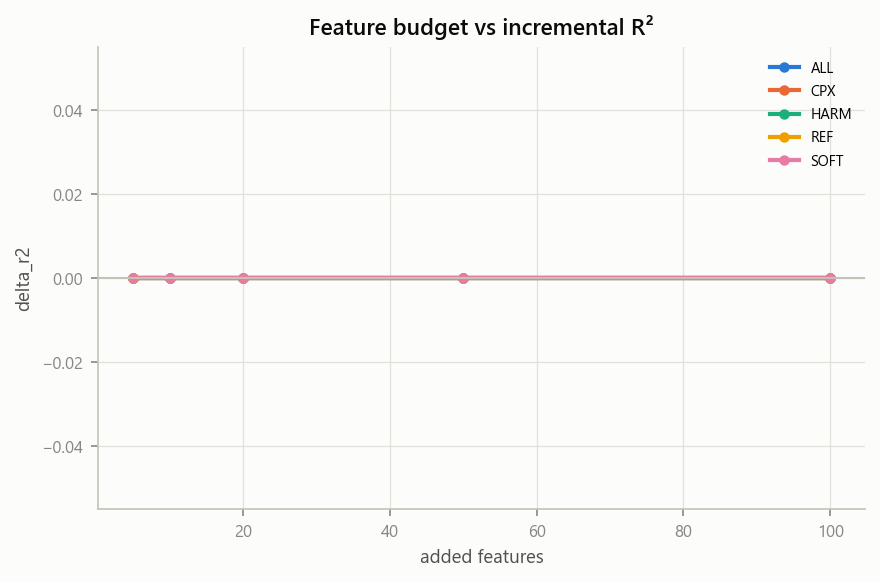

`family_value`

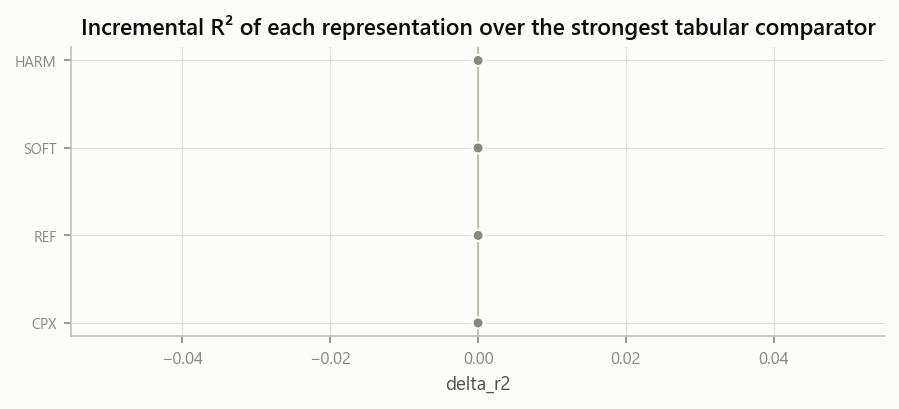

`leave_one_family_out`

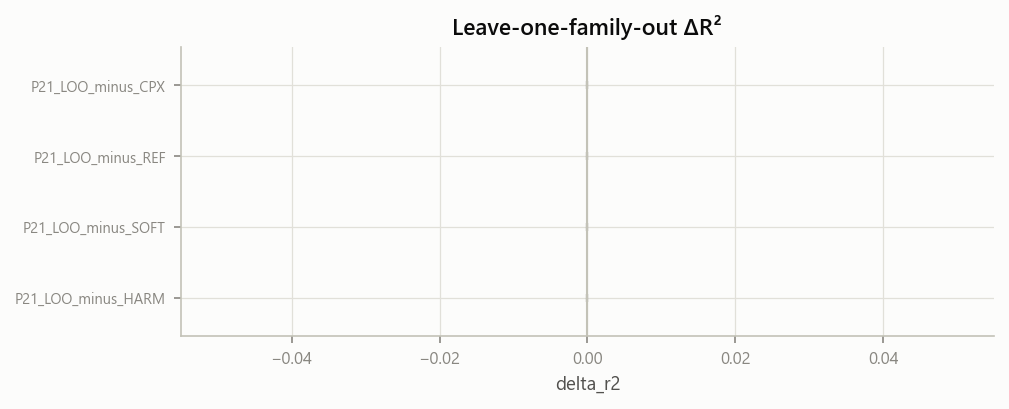

`model_comparison`

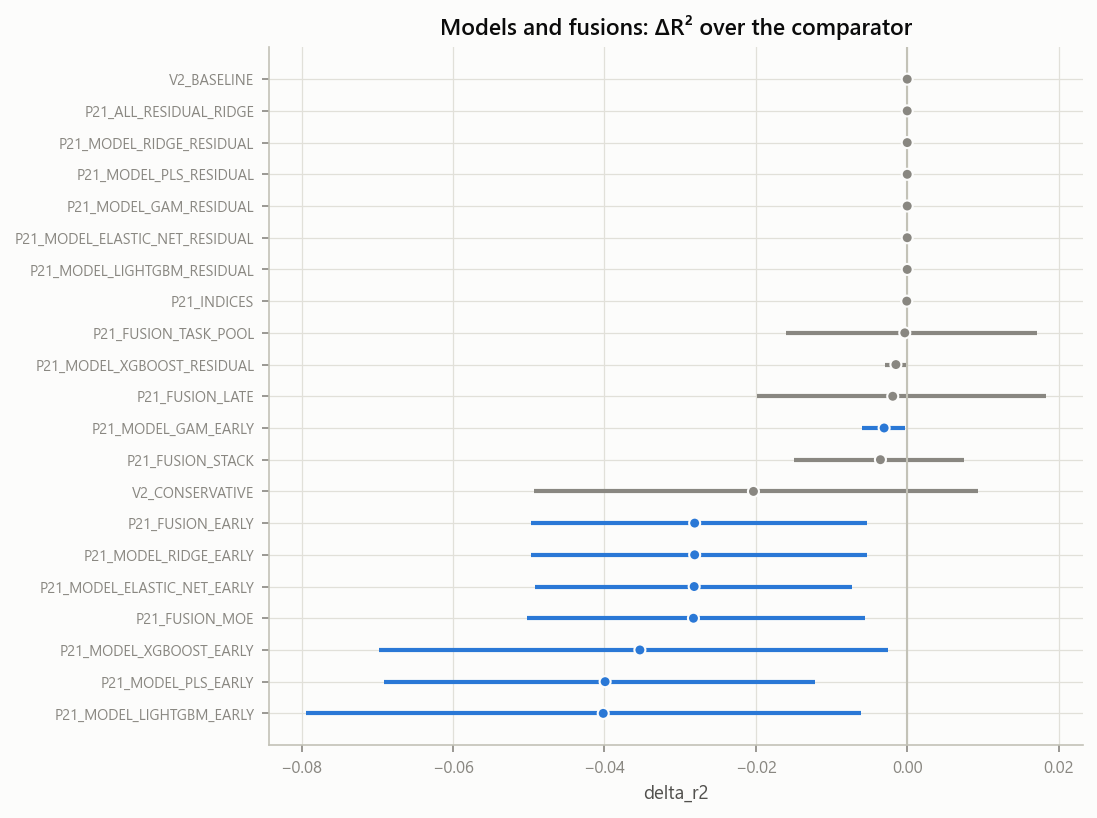

`pairwise_ablation`

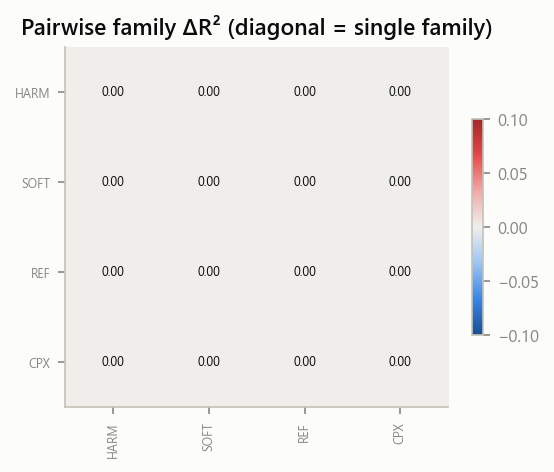

In [29]:
if RUN_PIPELINE:
    display(run_stage(pipe, "P21", RUN["P21"], FORCE, RUN_LOG))
show_stage_v2(ctx, "P21", ["baseline_verification", "providers", "family_value", "model_comparison_p21", "index_components",
                           "schedule"], TABLE_ROWS, SHOW_ALL_TABLES)

---
## 11 · P22 — Failure recovery and champion selection
Deployability checks (finite, extreme, quantile range, fold R², repeat SD, coverage) with quarantine; diagnosis and repair of the V1 task ensemble; failure populations and the modalities that recover them; candidate selection; report generation.

In [13]:
if RUN_PIPELINE:
    display(run_stage(pipe, "P22", RUN["P22"], FORCE, RUN_LOG))
show_stage_v2(ctx, "P22", ["deployability", "task_ensemble_diagnosis", "task_ensemble_repair", "recovery_matrix",
                           "candidates", "submissions", "generalization_summary"], TABLE_ROWS, SHOW_ALL_TABLES)
spec = ROOT / "models" / "v2_champion_spec.json"
if spec.exists():
    print(spec.read_text(encoding="utf-8")[:3000])

### P22 · Failure recovery and champion selection · `never_run`

**Findings (computed from this run's tables)**

- Stage P22 status: **never_run**. No findings are reported for it.

---
## 12 · Statistical validation
Pre-registered V2 hypotheses with their evidence tier (**exploratory** = discovery half / screening, **confirmatory** = pre-registered rule on held-out data, **leaderboard** = model selection), paired bootstrap CIs and FDR-adjusted values.

In [14]:
from wildspeech.v2.registry import v2_registries

v2r = v2_registries(ctx)
hyp = v2r.hypotheses.frame()
display(hyp)
if not hyp.empty and "evidence_tier" in hyp:
    display(hyp.groupby(["evidence_tier", "status"], dropna=False).size().rename("n").reset_index())
exp = v2r.experiments.frame()
if not exp.empty and "r2_mean" in exp:
    exp = exp.dropna(subset=["r2_mean"])
    display(Markdown(f"**Experiment registry** — {len(exp)} evaluations; best per scheme"))
    display(exp.sort_values("r2_mean", ascending=False).groupby("scheme").head(5))
for sid, name in (("P18", "within_correct_association"), ("P19", "within_correct_association"), ("P17", "student_residual_associations")):
    t = ctx.read_stage_table(sid, name)
    if t is not None and not t.empty and "tier" in t:
        display(Markdown(f"**{sid} {name}: confirmatory rows**"))
        display(t[t["tier"] == "confirmatory"].sort_values("p").head(TABLE_ROWS))

,hypothesis_id,statement,family,tested_in,rule,tier,status,updated_at
0,V2H01,Bandwidth/amplitude harmonization reduces reco...,HARMONIZATION,P16,selected variant's clip-level sample-rate AURO...,confirmatory,proposed,2026-11-20T17:17:46
1,V2H02,"Harmonized, item-conditioned acoustics add pre...",HARMONIZATION,P16,best variant's paired bootstrap delta-R2 CI > ...,confirmatory,proposed,2026-11-20T17:17:46
2,V2H03,Audio carries correctness information beyond i...,CORRECTNESS,P17,selected audio feature set's clip-level AUROC ...,confirmatory,proposed,2026-11-20T17:17:46
3,V2H04,Nested cross-fitted soft-correctness features ...,CORRECTNESS,P17,delta-R2 CI > 0 (repeated K-fold),confirmatory,proposed,2026-11-20T17:17:46
4,V2H05,Expected-text-conditioned phonetic features im...,PHONETIC,P18,PHON delta-R2 CI > 0 (repeated K-fold),confirmatory,proposed,2026-11-20T17:17:46
5,V2H06,Phonetic quality varies among officially corre...,PHONETIC,P18,>= 1 correct-only feature: discovery-half top-...,confirmatory,proposed,2026-11-20T17:17:46
6,V2H07,Reference-conditioned deviations improve stude...,REFERENCE,P19,REF delta-R2 CI > 0 (repeated K-fold),confirmatory,proposed,2026-11-20T17:17:46
7,V2H08,Deviation from comparable correct responses ca...,REFERENCE,P19,>= 1 correct-only deviation feature replicates...,confirmatory,proposed,2026-11-20T17:17:46
8,V2H09,A compact foundation-model representation impr...,FOUNDATION,P20,best evaluated layer's delta-R2 CI > 0,confirmatory,proposed,2026-11-20T17:17:46
9,V2H10,Intermediate encoder layers are more correctne...,FOUNDATION,P20,best layer < last layer and AUROC difference >...,exploratory,proposed,2026-11-20T17:17:46


---
## 13 · Complete ablation results
`outputs/V2/ablation_results.csv` and `outputs/V2/model_comparison.csv` (every value from this run).

In [15]:
abl = v2r.ablations.frame()
mod = v2r.models.frame()
if abl.empty:
    print("no ablations recorded yet (run P21)")
else:
    display(abl.sort_values(["kind", "delta_r2"], ascending=[True, False]))
    bud = abl[abl["kind"] == "budget"]
    if not bud.empty:
        display(Markdown("**Budget × representation (ΔR², repeated K-fold)**"))
        display(bud.assign(family=bud["name"].str.split("_").str[2]).pivot_table(index="family", columns="budget", values="delta_r2"))
if not mod.empty:
    display(Markdown("**Model comparison**"))
    display(mod.sort_values("delta_r2", ascending=False).head(40))

no ablations recorded yet (run P21)


---
## 14 · Scientific visualization atlas
Every figure registered in `outputs/V2/figure_index.csv` (each has its data table next to it): harmonization before/after, stability, correctness ROC/PR/calibration, phonetic differences and confusions, alignments, soft-correctness distributions, embedding maps, layer relevance, budget curves, residual associations, ablations, model uncertainty, failure recovery, generalization and GPU throughput.

In [16]:
idx = v2r.figures.frame()
display(idx[[c for c in ("stage", "name", "caption", "data_csv") if c in idx]] if not idx.empty else Markdown("_no figures yet_"))
figure_atlas(ctx)

_no figures yet_

figure index is empty — no V2 figure has been produced yet


---
## 15 · Submission generation (off by default)
Only validated, deployable candidates are submitted. `RUN_SUBMISSION = True` re-loads the V2 champion configuration (`models/v2_champion_config.json`, profile `V2_SUBMISSION`), extracts the test-split features the candidates need (resumable), fits on all training students, re-loads each fitted model from disk, checks the test predictions and validates every CSV against `submission_format.csv`. Test data are never used for discovery, normalisation, pseudo-labelling or selection.

In [17]:
if RUN_SUBMISSION:
    sctx, spipe = setup_v2("V2_SUBMISSION", root=ROOT)
    display(spipe.run(["P22"], force=["P22"]))
    show_stage_v2(sctx, "P22", ["submissions", "candidates", "test_feature_extraction"], TABLE_ROWS)
    for p in sorted((ROOT / "submissions" / "V2").glob("*.csv")):
        print(p.name, len(pd.read_csv(p)), "rows")
else:
    print("submission generation skipped (RUN_SUBMISSION = False)")
    s = ctx.read_stage_table("P22", "submissions")
    if s is not None:
        display(s)

submission generation skipped (RUN_SUBMISSION = False)


---
## 16 · Final conclusions and recommendations
Generated from this run's P16–P22 tables (`research_report_v2.conclusions` / `recommendations`) and written to `outputs/V2/scientific_report.html`.

In [18]:
from wildspeech.v2.research_report_v2 import TITLES, build_report, conclusions, recommendations, stage_findings

for sid in ("P16", "P17", "P18", "P19", "P20", "P21", "P22"):
    display(Markdown(f"**{sid} · {TITLES[sid]}**\n\n" + "\n".join(f"- {s}" for s in stage_findings(ctx, sid))))
display(Markdown("### Conclusions\n\n" + "\n".join(f"- {s}" for s in conclusions(ctx))))
display(Markdown("### Recommendations\n\n" + "\n".join(f"- {s}" for s in recommendations(ctx))))
rep = build_report(ctx)
print(rep)
if RUN_LOG:
    display(Markdown("**This session's runs**"))
    display(pd.concat(RUN_LOG, ignore_index=True))

**P16 · Acoustic domain harmonization**

- Stage P16 status: **never_run**. No findings are reported for it.

**P17 · Clip-level correctness intelligence**

- Stage P17 status: **never_run**. No findings are reported for it.

**P18 · Phonetic and linguistic intelligence**

- Stage P18 status: **never_run**. No findings are reported for it.

**P19 · Reference-conditioned speech modelling**

- Stage P19 status: **never_run**. No findings are reported for it.

**P20 · Speech foundation-model discovery**

- Stage P20 status: **never_run**. No findings are reported for it.

**P21 · Compact multimodal regression**

- Stage P21 status: **never_run**. No findings are reported for it.

**P22 · Failure recovery and champion selection**

- Stage P22 status: **never_run**. No findings are reported for it.

### Conclusions

- P21 has not produced family-level evidence yet; the central question cannot be answered from this run.

### Recommendations

- P18 (phonetic) produced no evidence in this run (never_run). Download eligible checkpoints locally, verify licence and training-data overlap in configs/foundation_models.yaml, then run V2_PHONETIC / V2_FOUNDATION.
- P20 (foundation-model) produced no evidence in this run (never_run). Download eligible checkpoints locally, verify licence and training-data overlap in configs/foundation_models.yaml, then run V2_PHONETIC / V2_FOUNDATION.

{'markdown': 'C:\\Users\\myben\\Downloads\\WildSpeech_P01\\WildSpeech_GPU\\outputs\\V2\\scientific_report.md', 'html': 'C:\\Users\\myben\\Downloads\\WildSpeech_P01\\WildSpeech_GPU\\outputs\\V2\\scientific_report.html', 'n_figures': 0}
